# <h2 style="text-align: center;">**DATA SCIENCE PROJECT**</h2>
# <h2 style="text-align: center;">**PREPARED BY:**</h2>
# <h2 style="text-align: center;">**LUQMAN ARIF BIN ZULKARNAIN**</h2>

---

## <h2 style="text-align: center;">**GEOSPATIAL ESTIMATION OF PADDY FIELD AREA VIA BINARY CLASSIFICATION AND ECONOMIC SIMULATION**</h2>

---

---
#### <h2 style="text-align: center;">**1.0 INTRODUCTION**</h2>
---

Rice is Malaysia's most important daily food and is vital for the country's national food security (Dorairaj & Govender, 2023). The state of Kedah, famously known as the "Rice Bowl of Malaysia," is the largest and most critical producer of the nation's domestic rice supply (Dorairaj & Govender, 2023). Paddy farming is highly important to the local economy because it provides stable jobs for thousands of rural families and reduces Malaysia's need to rely on imported rice from other countries (Dorairaj & Govender, 2023).

To properly manage and support this industry, accurate data on how much land is actively being farmed is required (dela Torre et al., 2021). Therefore, the main objective of this project is to accurately estimate the total area of paddy fields (in hectares) within the Pendang district of Kedah. To achieve this, the project uses satellite data and tests five advanced machine learning algorithms to see which one identifies the farm boundaries most accurately: Random Forest, Support Vector Machine (SVM), XGBoost, Multilayer Perceptron (MLP), and Convolutional Neural Networks (CNN) (Fatchurrachman et al., 2022; Suryono et al., 2022).

Beyond measuring the physical land, this project also estimates the financial returns to understand the real economic impact on the farmers. The economic simulation breaks down the farmer's livelihood into the following clear components:
*   **Land Allocation:** The average size of the paddy field operated by an individual farmer.
*   **Yield Production:** The estimated total weight of the paddy harvested by each farmer.
*   **Gross Yield Income:** The initial money earned from the harvest, which includes the base market price plus the government's RM500 per tonne price subsidy (*Skim Subsidi Harga Padi*).
*   **Input Subsidies:** Additional financial aids provided to the farmer per hectare to help cover plowing and fertilizer costs.
*   **Total Gross Revenue:** The combined total of the harvest income and all government subsidies before any farming expenses are paid.
*   **Total Production Cost:** The seasonal expenses required to operate the farm, such as machinery rentals, seeds, and labor.
*   **Net Profit:** The actual take-home income the farmer keeps after deducting all production costs from the gross revenue.
*   **Estimated Zakat Payable:** The obligatory 5% religious tax calculated directly from the farmer's net profit to be contributed back to the community.

---

#### <h2 style="text-align: center;">**2.0 DATASET DESCRIPTION**</h2>

---

### **2.1 Core Variables in the Dataset**

The dataset consists of 18 distinct satellite image variables processed into 100m resolution GeoTIFF grids to cover the Pendang study area. These variables capture unique multi-spectral, backscatter, and artificial illumination signatures retrieved from a combination of European Space Agency (ESA) Sentinel missions and NASA observational satellites.

#### **Data Source Descriptions**
1.  **ESA Sentinel-2 (Multispectral Instrument - MSI):** Provides high-resolution optical imagery. Used to derive all vegetation, water, soil, and built-up environmental indices based on the reflectance of specific electromagnetic wavelengths (e.g., Visible Light, Near-Infrared [NIR], and Shortwave-Infrared [SWIR]).
2.  **ESA Sentinel-1 (Synthetic Aperture Radar - SAR):** An active microwave sensor that penetrates cloud cover. It provides backscatter coefficients ($\sigma^0$) to determine surface roughness and structural geometries, which is highly effective for identifying flooded paddy fields regardless of weather.
3.  **NASA/NOAA Suomi-NPP (VIIRS DNB):** The Visible Infrared Imaging Radiometer Suite Day/Night Band captures low-light emissions, providing Night Time Light (NTL) data to proxy urbanization, human footprint, and infrastructure density.

#### **Index Formulas and Mathematical Derivations**

Below are the foundational spectral formulas used to derive the remote sensing variables. *(Note: Wavelength bands vary slightly by sensor, but represent standard optical and radar spectrums: Blue, Green, Red, NIR, SWIR1, and SWIR2).*

| Variable | Description | Mathematical Formula | 
|----------|-------------|----------------------|
| **AWEI** <br>*(Automated Water Extraction Index)* | Maximizes the separability of water and non-water pixels while suppressing shadows in urban or mountainous areas (Feyisa et al., 2014) | $$ \text{AWEI} = 4 \times (\text{Green} - \text{SWIR1}) - (0.25 \times \text{NIR} + 2.75 \times \text{SWIR2}) $$ |
| **BI** <br>*(Brightness Index)* | Sensitive to the brightness of bare soil and used to identify variations in soil moisture and salinity (Escadafal, 1989). | $$ \text{BI} = \sqrt{\frac{\text{Red}^2 + \text{Green}^2}{2}} $$ | 
| **BSI** <br>*(Bare Soil Index)* | Combines blue, red, NIR, and SWIR to capture soil variations while distinguishing them from vegetation canopies (Rikimaru et al., 2002). |  $$ \text{BSI} = \frac{(\text{SWIR1} + \text{Red}) - (\text{NIR} + \text{Blue})}{(\text{SWIR1} + \text{Red}) + (\text{NIR} + \text{Blue})} $$ |
| **BUI** <br>*(Built-Up Index)*  | Highlights urban or developed areas by contrasting the normalized difference of built-up lands against vegetation (He et al., 2010).| $$ \text{BUI} = \text{NDBI} - \text{NDVI} $$ | 
| **EVI** <br>*(Enhanced Vegetation Index)* | Optimized to improve the vegetation signal with improved sensitivity in high biomass regions and improved vegetation monitoring through a de-coupling of the canopy background signal and a reduction in atmosphere influences (Huete et al., 2002). | $$ \text{EVI} = 2.5 \times \frac{\text{NIR} - \text{Red}}{\text{NIR} + 6 \times \text{Red} - 7.5 \times \text{Blue} + 1} $$ |
| **IBI** <br>*(Index-based Built-up Index)* | A composite index that enhances built-up areas by suppressing vegetation and water noise (Xu, 2008). | $$ \text{IBI} = \frac{\frac{\text{SWIR1} - \text{NIR}}{\text{SWIR1} + \text{NIR}} - \frac{1}{2} \left( \frac{\text{NIR} - \text{Red}}{\text{NIR} + \text{Red}} + \frac{\text{Green} - \text{SWIR1}}{\text{Green} + \text{SWIR1}} \right)}{\frac{\text{SWIR1} - \text{NIR}}{\text{SWIR1} + \text{NIR}} + \frac{1}{2} \left( \frac{\text{NIR} - \text{Red}}{\text{NIR} + \text{Red}} + \frac{\text{Green} - \text{SWIR1}}{\text{Green} + \text{SWIR1}} \right)} $$ |
| **MNDWI** <br>*(Modified NDWI)* | Uses the SWIR band instead of NIR to suppress noise from built-up land, making open water features more distinct (Xu, 2006). | $$ \text{MNDWI} = \frac{\text{Green} - \text{SWIR1}}{\text{Green} + \text{SWIR1}} $$ |
| **MSAVI** <br>*(Modified SAVI)* | Minimizes the effect of bare soil on the SAVI index, specifically useful in early stages of paddy planting where soil background is highly visible (Qi et al., 1994). | $$ \text{MSAVI} = \frac{2 \times \text{NIR} + 1 - \sqrt{(2 \times \text{NIR} + 1)^2 - 8 \times (\text{NIR} - \text{Red})}}{2} $$ |
| **NDBI** <br>*(Normalized Difference Building Index)* | Highlights urban areas where there is typically a higher reflectance in the SWIR band compared to the NIR band (Zha et al., 2003). | $$ \text{NDBI} = \frac{\text{SWIR1} - \text{NIR}}{\text{SWIR1} + \text{NIR}} $$ | 
| **NDSI** <br>*(Normalized Difference Soil Index)* | Exploits the spectral difference between SWIR and NIR to enhance the presence of bare soils and sandy surfaces (Rogers & Kearney, 2004). | $$ \text{NDSI} = \frac{\text{SWIR1} - \text{NIR}}{\text{SWIR1} + \text{NIR}} $$ |
| **NDVI** <br>*(Normalized Difference Vegetation Index)* | The most widely used index for quantifying vegetation greenness and density based on the strong absorption of Red light and strong reflection of NIR by healthy chlorophyll (Rouse et al., 1974). | $$ \text{NDVI} = \frac{\text{NIR} - \text{Red}}{\text{NIR} + \text{Red}} $$ |
| **NDWI** <br>*(Normalized Difference Water Index)* | Delineates open water features by leveraging the green light reflectance and NIR absorption properties of water (McFeeters, 1996). | $$ \text{NDWI} = \frac{\text{Green} - \text{NIR}}{\text{Green} + \text{NIR}} $$ |
| **NTL** <br>*(Night Time Light)* | Unlike spectral indices, NTL is a direct measurement of artificial visible/near-infrared radiance ($L_{rad}$) emitted from the Earth's surface at night, used to proxy economic activity and rural development (Elvidge et al., 2013). | $$ \text{NTL} = L_{rad} \; (\text{nanoWatts} / \text{cm}^2 / \text{sr}) $$ |
| **SAR_VH & SAR_VV** <br>*(Synthetic Aperture Radar)* | Active microwave backscatter. VH (Vertical transmit, Horizontal receive) is highly sensitive to volume scattering (crop canopies), while VV (Vertical transmit, Vertical receive) is sensitive to surface scattering (water and bare soil). The digital number ($DN$) is converted to the backscatter coefficient ($\sigma^0$) in decibels (Filipponi, 2019). | $$ \sigma^0 (\text{dB}) = 10 \cdot \log_{10}(DN^2) $$ | 
| **SAVI** <br>*(Soil-Adjusted Vegetation Index)* | Introduces a soil brightness correction factor ($L$) to minimize soil background influences in areas with low vegetative cover (Huete, 1988). The standard $L$ value is $0.5$. | $$ \text{SAVI} = \frac{\text{NIR} - \text{Red}}{\text{NIR} + \text{Red} + L} \times (1 + L) $$ | 
| **SVI** <br>*(Soil Vulnerability Index)* | Unlike purely spectral indices, the Soil Vulnerability Index in agricultural contexts is typically an integrated geospatial model rather than a simple 2-band spectral ratio. It combines slope, soil erodibility, and runoff classifications to map areas prone to nutrient and soil loss (Thompson et al., 2020). |  *Integrated Geospatial Model* |
| **UI** <br>*(Urban Index)*| Exploits the inverse relationship between the high reflectance of SWIR2 and low reflectance of NIR in built environments (Kawamura et al., 1996). | $$ \text{UI} = \frac{\text{SWIR2} - \text{NIR}}{\text{SWIR2} + \text{NIR}} $$ |

---

#### <h2 style="text-align: center;">**3.0 METHODOLOGY**</h2>

---

This project establishes a data-driven approach to map paddy fields in Pendang, Kedah, and translate those physical land measurements into real-world economic impacts for local farmers. The workflow is divided into five distinct stages. 

---

#### **3.1 Raw Satellite Image Data Retrieval**

The initial step of the workflow retrieves 18 satellite image variables for the Pendang area from 1st January 2023 until 31st December 2023 using the Google Earth Engine platform. The automated pipeline filters the Sentinel-2 image collection to retain only scenes with less than 7.03% cloud cover, subsequently applying advanced masking algorithms to strip away remaining opaque and cirrus clouds. 

After dynamically calculating specific environmental indices pixel-by-pixel, a temporal median reducer flattens the year's overlapping imagery into a single, highly stable composite to eliminate seasonal anomalies and transient shadows. Finally, the processed composite is clipped to the Pendang boundary and exported as a 100-meter resolution GeoTIFF (EPSG:4326), perfectly formatting the spatial matrices for the upcoming machine learning feature engineering phase.

---

#### **3.2 Feature Engineering**
The first step involves extracting spatial data from 18 different satellite image variables specifically within the Pendang boundary. Because satellite images often have blank spots caused by cloud cover or sensor errors, a mathematical method called K-Nearest Neighbors (KNN) using 10 neighbors is applied. This method intelligently fills in missing data by looking at the closest surrounding pixels, ensuring the machine learning models do not fail due to empty values (Troyanskaya et al., 2001).

---

#### **3.3 Data Pre-Processing**
Once the satellite data is extracted, it must be cleaned and organized. The script renames the geographic coordinates to standard "LONGITUDE" and "LATITUDE" headers and removes un-processed raw variables. This allows the system to easily identify and delete any duplicate geographic data points, ensuring that every piece of information fed into the model represents a unique physical location and prevents data redundancy (McKinney, 2010; Han et al., 2011).

---

#### **3.4 Data Integration**
This step connects the actual ground-truth field observations (known farm locations) with the satellite images by projecting all datasets into a shared Cartesian Coordinate Reference System (EPSG:3375). Standard GPS coordinates measure distance in degrees, which can distort physical distance depending on the curvature of the Earth. EPSG:3375 is a specific localized map projection that measures distance in exact meters, allowing for highly accurate and reliable spatial calculations (Bolstad, 2016).

Next, the system pairs each ground-truth sample with its geographically closest satellite pixel using spatial nearest-neighbour matching. To guarantee accuracy, a strict 50-meter maximum distance threshold is enforced any matches further apart than this are automatically dropped from the study. Enforcing a strict distance limit ensures that ground-truth data is only linked to satellite pixels that genuinely represent the exact same physical location, preventing the model from learning incorrect or misaligned environmental patterns from distant, unrelated areas (Bivand et al., 2013).

---

#### **3.5 Model Development**
The pipeline tests five advanced machine learning and deep learning models to determine which architecture draws the most accurate map of the paddy fields: Random Forest, Support Vector Machine (SVM), XGBoost, Multilayer Perceptron (MLP), and Convolutional Neural Networks (CNN). 

To rigorously test how well these models perform, **5-Fold Spatial Block Cross-Validation** is utilized, which divides the map into roughly 2-kilometer geographic grid blocks. This forces the model to predict on entirely unseen geographical regions, ensuring it actually learns the visual signatures of paddy fields rather than just memorizing local pixel clusters (Roberts et al., 2017).

---

##### **3.5.1 Model Algorithms and Formulas**
The study adopts the following foundational algorithms to classify the satellite data (where $x$ represents the input satellite features and $\hat{y}$ represents the predicted paddy class):

1.  **Random Forest (RF):** An ensemble learning method that constructs multiple decision trees ($h$) and outputs the most frequent prediction (mode).
    *   **Formula:** $$ \hat{y} = \text{mode}\{h_1(x), h_2(x), ..., h_B(x)\} $$

Highly robust against overfitting and handles non-linear environmental data exceptionally well without requiring extensive scaling (Breiman, 2001).

2.  **Support Vector Machine (SVM):** Finds the optimal boundary (hyperplane) that separates paddy from non-paddy pixels by maximizing the margin between them using a kernel function $K$.
    *   **Formula:** $$ f(x) = \text{sign}\left(\sum_{i=1}^{n} \alpha_i y_i K(x, x_i) + b\right) $$

Highly effective in high-dimensional spaces, making it ideal for processing multi-spectral satellite variables (Cortes & Vapnik, 1995).

3.  **eXtreme Gradient Boosting (XGBoost):** An additive model that trains decision trees sequentially ($f_k$), where each new tree corrects the errors made by the previous ones.
    *   **Formula:** $$ \hat{y}_i = \sum_{k=1}^K f_k(x_i) $$

Optimized for speed and performance, often yielding the highest accuracy in structured geospatial tabular data (Chen & Guestrin, 2016).

4.  **Multilayer Perceptron (MLP):** A traditional feedforward neural network that learns complex patterns through interconnected hidden layers, weights ($W$), and activation functions ($\sigma$).
    *   **Formula:** $$ f(x) = \sigma(W_2 \sigma(W_1 x + b_1) + b_2) $$

Capable of modeling highly complex, non-linear relationships across the 18 satellite variables (Goodfellow et al., 2016).

5.  **Convolutional Neural Network (CNN):** Utilizes 1D convolutional operations ($*$) to automatically extract deep spectral features from the input variables.
    *   **Formula:** $$ h_j = \sigma\left(\sum_k h_k * w_{kj} + b_j\right) $$

While typically used for images, 1D-CNNs excel at finding hidden spectral signatures across multiple satellite bands (Goodfellow et al., 2016).

---

##### **3.5.2 Evaluation Method**
To thoroughly assess the final performance of each model, the system evaluates predictions on a separate hold-out test set. The performance is quantified using a Confusion Matrix which categorizes results into True Positives ($TP$), True Negatives ($TN$), False Positives ($FP$), and False Negatives ($FN$) and the following core metrics:

*   **Accuracy:** The overall proportion of correctly predicted pixels.
    $$ \text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} $$

*   **Precision:** Evaluates the model's exactness. It measures how many of the predicted paddy pixels were actually paddy (minimizes over-predicting).
    $$ \text{Precision} = \frac{TP}{TP + FP} $$

*   **Recall:** Evaluates the model's completeness. It measures how many of the actual paddy pixels were successfully identified (minimizes missing actual farms).
    $$ \text{Recall} = \frac{TP}{TP + FN} $$

*   **F1-Score:** The harmonic mean of Precision and Recall. While standard accuracy can be misleading if the map has vastly more non-paddy than paddy areas, the F1-Score provides a balanced measure critical for reliable agricultural mapping (Sokolova & Lapalme, 2009).

    $$ \text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}} $$
*   **ROC-AUC (Receiver Operating Characteristic - Area Under Curve):** Measures the model's overarching ability to successfully distinguish between paddy and non-paddy classes across all possible classification thresholds. An excellent holistic metric for comparing which machine learning model separates the two classes most effectively (Fawcett, 2006).

---

#### **3.6 Yield Production & Economic Simulation**
The final step translates the spatial predictions into financial metrics for the farming community. Assuming the total estimated paddy area is shared equally among 10,000 farmers, the simulation uses regional benchmarks (such as 4.7 tonnes of yield per hectare) to estimate livelihoods. 

The simulation relies on the following foundational formulas as shown in table below:


| Economic Component | Formula | Description |
| :--- | :--- | :--- |
| **Land Allocation per Farmer** | $\text{Land (ha)} = \frac{\text{Total Estimated Paddy Area}}{\text{Total Number of Farmers}}$ | Land consolidation and equitable distribution modeling among local farming cohorts is essential for evaluating regional food security and individual smallholder livelihoods within the Muda Agricultural Development Authority (MADA) granary areas (Omar et al., 2024). |
| **Yield Production** | $\text{Total Yield (tonnes)} = \text{Land (ha)} \times 4.7$ | The average paddy yield in the MADA region operates as a baseline of approximately 4.7 to 5.0 metric tonnes per hectare, depending on seasonal climate factors and technology adoption (Ministry of Agriculture and Food Security, 2024). |
| **Gross Yield Income** <br>*(including Government Subsidy)* | $\text{Gross Yield Income} = \text{Total Yield} \times (1500 + 500)$ | Combines the base market price (RM1,500) with the Skim Subsidi Harga Padi (SSHP), which was officially increased to RM500 per metric tonne to safeguard farmer incomes against rising living costs (Bernama, 2023). |
| **Input Subsidies** <br>*(Plowing & Fertilizers)* | $\text{Total Subsidies} = \text{Land (ha)} \times (300 + 300)$ | Area-based input subsidies, including RM300 for plowing (Insentif Pembajakan) and RM300 for fertilizers/pesticides, are critical government interventions designed to offset the initial capital expenditure required for land preparation per hectare (Business Today, 2026). |
| **Total Gross Revenue** | $\text{Total Gross Revenue} = \text{Gross Yield Income} + \text{Total Subsidies}$ | Represents the aggregate financial inflow per farmer before operational deductions, heavily reliant on the combination of actual crop performance and state agricultural support mechanisms. |
| **Total Production Cost** | $\text{Total Cost} = \text{Land (ha)} \times 5500$ | The seasonal cultivation expenses encompassing machinery rentals, paid labor, seeds, pesticides, and logistics average roughly RM5,500 per hectare for modern commercial paddy farming in Malaysia (Omar et al., 2024). |
| **Net Profit** | $\text{Net Profit} = \text{Total Gross Revenue} - \text{Total Cost}$ | Determines the actual take-home socioeconomic value generated per smallholder after accounting for all seasonal operational liabilities. |
| **Zakat Payable** <br>*(Religious Tax)* | $\text{Zakat} = \text{Net Profit} \times 0.05$ | According to the Lembaga Zakat Negeri Kedah (LZNK), the obligatory religious tax for paddy cultivated using modern technology (where costs of irrigation, machinery, and labor are borne by the farmer) is set at 5% of the net income, provided the total harvest meets the *nisab* (minimum threshold) of 1,306 kg (Lembaga Zakat Negeri Kedah, n.d.). |

---

#### <h2 style="text-align: center;">**4.0 PYTHON WORKFLOW**</h2>

---

### **Step 1: Feature Engineering**
*Filter, clean, and impute raw satellite data for the study area.*

* **Spatial Filtering:** Extracts 18 raw satellite image variables strictly within the Pendang boundary map. It converts the continuous grid into exact map shapes to filter out empty or out-of-bounds pixels.
* **Missing Data Imputation:** Intelligently fills blank spots (caused by cloud cover or sensor errors) using a **K-Nearest Neighbors (KNN)** technique based on the 10 closest surrounding pixels.
* **Data Scaling:** Mathematically adjusts and scales features into a standard range to prevent extreme values from skewing the machine learning algorithms.
* **Output:** A clean CSV table ready for ML training, alongside a Shapefile for visual map inspection.

---

### **Step 2: Data Pre-Processing**
*Standardize the dataset structure for seamless machine learning integration.*

* **Coordinate Standardization:** Renames raw 'x' and 'y' columns to formal **'LONGITUDE'** and **'LATITUDE'** headers.
* **Spatial Uniqueness:** Identifies and drops any duplicate geographic data points.
* **Redundancy & Leakage Prevention:** Completely removes unprocessed variables (tagged with `_original`) and simplifies predictive features by stripping the `_imputed` suffix.
* **Output:** A finalized, highly refined, and clean dataset optimized for model training.

---

### **Step 3: Data Integration**
*Link actual ground-truth field data with corresponding satellite imagery.*

* **CRS Alignment:** Loads boundaries and data points into a shared coordinate system (**EPSG:3375**) to ensure distances are accurately measured in meters.
* **Spatial Pairing:** Pairs each real-world sample to its nearest satellite pixel, dropping any pairs that are more than 50 meters apart to guarantee high accuracy.
* **Data Cleansing:** Deletes leftover map shapes and non-numeric text.
* **Output:** A dataset consisting of pure numbers, perfectly merged and ready for machine learning ingestion.

---

### **Step 4: Model Development**
*Automate the training, evaluation, and spatial deployment of advanced ML architectures.*

* **Algorithms Deployed:** XGBoost, Random Forest, Support Vector Machine (SVM), Multi-Layer Perceptron (MLP), and a 1D Convolutional Neural Network (CNN).
* **Optimization & Benchmarking:** Optimizes hyperparameters via randomized search CV and evaluates models using F1-Score, ROC-AUC, feature importance, and confusion matrices.
* **Rigorous Validation:** Employs **5-fold Spatial Block Cross-Validation** (divided into 2km geographic grids) to ensure models generalize geographically rather than just memorizing local pixel clusters.
* **Output:** Predicted paddy presence across the unlabelled study area, automatically computed total acreage, GIS-ready raster **GeoTIFFs**, and transparent spatial error maps.

---

### **Step 5: Yield Production & Economic Simulation**
*Translate spatial machine learning predictions into tangible agricultural-economic metrics.*

* **Yield Calculation:** Distributes the estimated total paddy area equally across 10,000 smallholder farmers, calculating harvest yield using a regional benchmark of **4.7 metric tonnes per hectare**.
* **Revenue & Subsidies:** Formulates total gross revenue by combining base market value with the government's *Skim Subsidi Harga Padi (SSHP)* and area-based input subsidies for plowing and fertilizers.
* **Profitability & Obligations:** Deducts seasonal production costs to establish net profit and automatically computes the mandatory **5% zakat contribution** for each farmer.
* **Output:** A comprehensive financial report linking satellite-derived geographic footprints directly to real-world livelihoods, profitability, and socio-religious economic obligations.

In [1]:
#========================================================================================================================================
# STEP (0) : IMPORT NECESSARY LIBRARIES
#========================================================================================================================================

import rasterio # Import the rasterio library for reading and writing geospatial raster data (GeoTIFFs)
import pandas as pd # Import pandas for data manipulation and analysis using DataFrames
import numpy as np # Import numpy for numerical operations and handling arrays
from rasterio.transform import xy # Import the xy function from rasterio to convert array indices (row, col) to spatial coordinates (x, y)
from sklearn.impute import KNNImputer # Import KNNImputer from scikit-learn to fill missing values using the k-Nearest Neighbors approach
from sklearn.preprocessing import PowerTransformer, MinMaxScaler # Import PowerTransformer and MinMaxScaler for data normalization and scaling
import geopandas as gpd # Import geopandas for working with geospatial data in a tabular format (GeoDataFrames)
from shapely.geometry import Polygon # Import Polygon from shapely to create bounding boxes (geometries) for each pixel
from tqdm import tqdm  # Import tqdm to display a progress bar during lengthy loops

import os # Import the os module to handle file and directory operations
import warnings # Import warnings to suppress unnecessary output warnings during execution
import pandas as pd # Import pandas for data manipulation and tabular data processing
import numpy as np # Import numpy for numerical operations and array handling
import matplotlib.pyplot as plt # Import matplotlib.pyplot for creating static, interactive, and animated visualizations
import seaborn as sns # Import seaborn for statistical data visualization and styling matplotlib plots
import joblib # Import joblib for saving and loading trained machine learning models
import geopandas as gpd # Import geopandas for spatial data manipulation (GeoDataFrames)
import rasterio # Import rasterio for reading and writing geospatial raster datasets
from rasterio.transform import from_origin # Import from_origin to define the spatial transformation matrix for the output raster
from rasterio.features import rasterize # Import rasterize to convert vector geometries (points/polygons) into raster pixel arrays

# Scikit-Learn & ML Models
# Import tools for splitting data, hyperparameter tuning, and spatial cross-validation
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GroupKFold # Import tools for splitting data, hyperparameter tuning, and spatial cross-validation
from sklearn.pipeline import Pipeline # Import Pipeline to chain preprocessing and modeling steps together
from sklearn.impute import SimpleImputer # Import SimpleImputer to handle missing values by replacing them with statistical estimates
from sklearn.preprocessing import StandardScaler # Import StandardScaler to normalize feature distributions to a mean of 0 and variance of 1
from sklearn.base import clone # Import clone to construct a new unfitted estimator with the same parameters
from sklearn.ensemble import RandomForestClassifier # Import RandomForestClassifier, an ensemble learning method using multiple decision trees
from sklearn.svm import SVC # Import Support Vector Classifier for finding hyperplanes that separate classes
from sklearn.neural_network import MLPClassifier # Import Multi-Layer Perceptron Classifier, a classic feed-forward artificial neural network
from xgboost import XGBClassifier # Import XGBClassifier, a highly efficient and scalable gradient boosting framework

# Deep Learning
import tensorflow as tf # Import the main TensorFlow library for deep learning operations
from tensorflow.keras.models import Sequential # Import Sequential to build a neural network layer by layer
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, Reshape, Input # Import necessary layers: Convolutional (1D), Pooling, Flattening, Dense (fully connected), Dropout (regularization), Reshape, and Input
from tensorflow.keras.optimizers import Adam # Import the Adam optimizer, an efficient gradient descent algorithm
from scikeras.wrappers import KerasClassifier # Import KerasClassifier to wrap the TensorFlow/Keras model so it works seamlessly within Scikit-Learn pipelines

# Metrics & Interpretability
from sklearn.inspection import permutation_importance # Import permutation_importance to evaluate feature importance for models that don't have native methods
from sklearn.calibration import calibration_curve # Import calibration_curve to assess how well predicted probabilities align with true outcomes
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report, confusion_matrix,
    roc_curve, precision_recall_curve, average_precision_score, cohen_kappa_score
) # Import evaluation metrics to assess classification model performance

warnings.filterwarnings("ignore") # Suppress all runtime warnings to keep the console output clean and readable
sns.set_style("whitegrid") # Set the default visual theme for seaborn plots to 'whitegrid' for cleaner charts
plt.rcParams["figure.dpi"] = 110 # Increase the default screen display resolution for matplotlib figures to 110 DPI
plt.rcParams["savefig.dpi"] = 150 # Increase the resolution of saved matplotlib figures to 150 DPI for high-quality exports

In [2]:
#===================================================================
# STEP (1) : FEATURE ENGINEERING
#===================================================================

# Define a dictionary containing the variable names as keys and their corresponding GeoTIFF file paths as values
geotiff_files = {
    'AWEI': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/AWEI_Pendang_2023_100m.tif",    
    'BI': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/BI_Pendang_2023_100m.tif",
    'BSI': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/BSI_Pendang_2023_100m.tif",
    'BUI': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/BUI_Pendang_2023_100m.tif",
    'EVI': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/EVI_Pendang_2023_100m.tif",
    'IBI': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/IBI_Pendang_2023_100m.tif",
    'MDWI': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/MNDWI_Pendang_2023_100m.tif",
    'MSAVI': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/MSAVI_Pendang_2023_100m.tif",
    'NDBI': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/NDBI_Pendang_2023_100m.tif",
    'NDSI': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/NDSI_Pendang_2023_100m.tif",
    'NDVI': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/NDVI_Pendang_2023_100m.tif",
    'NDWI': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/NDWI_Pendang_2023_100m.tif",
    'NTL': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/NTL_Pendang_2023_100m.tif",
    'SAR_VH': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/SAR_VH_Pendang_2023_100m.tif",
    'SAR_VV': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/SAR_VV_Pendang_2023_100m.tif",
    'SAVI': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/SAVI_Pendang_2023_100m.tif",
    'SVI': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/SVI_Pendang_2023_100m.tif",
    'UI': "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/GeoTIFF%20File/UI_Pendang_2023_100m.tif"
}

# Define a list to strictly maintain the order of the variables during processing
# This ensures consistency across DataFrames and exported files
variable_order = [
    'AWEI',
    'BI',
    'BSI',
    'BUI',
    'EVI',
    'IBI',
    'MDWI',
    'MSAVI',
    'NDBI',
    'NDSI',
    'NDVI',
    'NDWI',
    'NTL',
    'SAR_VH',
    'SAR_VV',
    'SAVI',
    'SVI',
    'UI'
]

# Define the file path for the boundary shapefile of the study area (Pendang)
shapefile_path = "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/Shape%20File/Pendang.shp"

# Function to open a GeoTIFF file, extract its raster array, and its spatial transform matrix
def read_geotiff(file_path):
    # Open the raster file safely using a context manager
    with rasterio.open(file_path) as src:
        # Read the first band of the raster as a NumPy array
        data = src.read(1)
        # Extract the spatial transformation metadata to convert pixels to coordinates
        transform = src.transform
        # Return both the raster data and the transform object
        return data, transform

# Function to extract pixel values and spatial coordinates from all specified GeoTIFF files
def extract_values_from_geotiffs(files):
    # Initialize a dictionary to store lists of X coordinates, Y coordinates, and Shapely Geometries
    data_dict = {
        'x': [],
        'y': [],
        'geometry': []
    }
    
    # Get the file path of the very first raster in the dictionary to establish the grid dimensions
    first_file = list(files.values())[0]
    # Read the data and transform matrix from this first file
    first_data, transform = read_geotiff(first_file)
    
    # Extract the total number of rows (height) and columns (width) from the raster array
    height, width = first_data.shape

    # Initialize a progress bar for the nested loop (total iterations = height * width)
    with tqdm(total=height * width, desc="Reading GeoTIFF files", unit="pixels") as pbar:
        # Loop through every row in the raster grid
        for row in range(height):
            # Loop through every column in the raster grid
            for col in range(width):
                # Calculate the X and Y coordinates for the center of the current pixel
                x_center, y_center = xy(transform, row, col)
                # Calculate the X and Y coordinates for the upper-left corner of the pixel
                x_left, y_top = xy(transform, row, col, offset='ul')
                # Calculate the X and Y coordinates for the lower-right corner of the pixel
                x_right, y_bottom = xy(transform, row, col, offset='lr')

                # Create a square Polygon representing the exact footprint of the pixel
                polygon = Polygon([
                    (x_left, y_top),       # Top-left vertex
                    (x_right, y_top),      # Top-right vertex
                    (x_right, y_bottom),   # Bottom-right vertex
                    (x_left, y_bottom),    # Bottom-left vertex
                    (x_left, y_top)        # Close the polygon back at top-left
                ])

                # Append the calculated center X coordinate to the dictionary
                data_dict['x'].append(x_center)
                # Append the calculated center Y coordinate to the dictionary
                data_dict['y'].append(y_center)
                # Append the Shapely Polygon to the dictionary
                data_dict['geometry'].append(polygon)
                
                # Loop through every variable and its file path in the provided dictionary
                for key, file in files.items():
                    # Read the raster data for the current variable
                    data, _ = read_geotiff(file)
                    # Extract the specific pixel value at the current row and column
                    value = data[row, col]
                    # If this variable isn't in our dictionary yet, initialize an empty list for it
                    if key not in data_dict:
                        data_dict[key] = []
                    # Append the extracted pixel value to the corresponding variable's list
                    data_dict[key].append(value)

                # Update the progress bar by 1 after fully processing a single pixel
                pbar.update(1)
    
    # Convert the populated dictionary into a Pandas DataFrame for easier manipulation
    return pd.DataFrame(data_dict)

# Function to handle missing data (NaN) using the k-Nearest Neighbors imputation method
def impute_with_knn(df, features, n_neighbors):
    # Initialize the KNNImputer with the specified number of neighbors
    imputer = KNNImputer(n_neighbors=n_neighbors)
    # Create a copy of the dataframe to avoid modifying the original data
    df_imputed = df.copy()
    # Fit the imputer on the specified features and replace NaNs with estimated values
    df_imputed[features] = imputer.fit_transform(df[features])
    # Return the new dataframe containing no missing values
    return df_imputed

# Function to export a Pandas DataFrame containing Shapely geometries back into an ESRI Shapefile
def save_as_shapefile(df, shapefile_path):
    # Convert the standard DataFrame into a GeoDataFrame, defining the geometry column and spatial reference (WGS84)
    gdf = gpd.GeoDataFrame(df, geometry='geometry', crs="EPSG:4326")
    # Export the GeoDataFrame to the specified file path using the ESRI Shapefile driver
    gdf.to_file(shapefile_path, driver='ESRI Shapefile')

# Read the regional boundary shapefile into a GeoDataFrame
shapefile_data = gpd.read_file(shapefile_path)

# Execute the extraction function to build a DataFrame of all pixel values across all raster layers
df = extract_values_from_geotiffs(geotiff_files)

# Convert the extracted tabular data into a GeoDataFrame to enable spatial operations
gdf = gpd.GeoDataFrame(df, geometry='geometry', crs="EPSG:4326")
# Perform a spatial join to keep only the raster pixels that intersect with the Pendang shapefile boundary
merged_data = gpd.sjoin(gdf, shapefile_data, how="left", predicate='intersects')

# Remove rows (pixels) where all the satellite image variables are missing (NaN), as they represent empty space
merged_data_filtered = merged_data.dropna(how='all', subset=variable_order)

# Set the number of neighbors to use for KNN imputation
n_neighbors = 10  
# Apply the KNN imputation function to fill in any remaining partial missing data
df_imputed = impute_with_knn(merged_data_filtered, variable_order, n_neighbors)

# Make a copy of the spatially filtered data to prepare for the final CSV compilation
compiled_data = merged_data_filtered.copy()

# Loop through each variable to explicitly label and store both original and imputed versions side-by-side
for variable in variable_order:
    # Store the raw, unaltered original data under a new column name
    compiled_data[f'{variable}_original'] = merged_data_filtered[variable]
    # Store the KNN-imputed data under a new column name
    compiled_data[f'{variable}_imputed'] = df_imputed[variable]

# Extract the column names belonging to the original boundary shapefile attributes
shapefile_columns = shapefile_data.columns.tolist()
# Remove the 'geometry' column from this list to prevent duplicate geometry columns in our CSV
shapefile_columns.remove('geometry')  

# Initialize a list of final column names starting with coordinates, geometry, and shapefile attributes
csv_columns = ['x', 'y', 'geometry'] + shapefile_columns
# Append the names of our newly created original and imputed columns to the list
for variable in variable_order:
    csv_columns += [f'{variable}_original', f'{variable}_imputed']

# Reorder the compiled_data dataframe so it strictly follows the structure defined in csv_columns
compiled_data = compiled_data[csv_columns]

# Reset the index to clean up gaps left by the dropna() and sjoin() functions
compiled_data = compiled_data.reset_index(drop=True)

# Print a final success message to the console indicating the script has finished its workflow
print(f"Data imputation and compilation complete.")

compiled_data.head(20)

Reading GeoTIFF files: 100%|██████████| 110633/110633 [3:41:21<00:00,  8.33pixels/s] 


Data imputation and compilation complete.


,x,y,geometry,id,name,code_state,state,AWEI_original,AWEI_imputed,BI_original,...,SAR_VH_original,SAR_VH_imputed,SAR_VV_original,SAR_VV_imputed,SAVI_original,SAVI_imputed,SVI_original,SVI_imputed,UI_original,UI_imputed
0,100.608168,6.123366,"POLYGON ((100.60772 6.12382, 100.60862 6.12382...",pendang,Pendang,2.0,KDH,-0.041412,-0.041412,0.336921,...,-15.671479,-15.671479,-8.786675,-8.786675,0.314285,0.314285,-0.222801,-0.222801,1.106101,1.106101
1,100.609066,6.123366,"POLYGON ((100.60862 6.12382, 100.60952 6.12382...",pendang,Pendang,2.0,KDH,-0.385488,-0.385488,0.583528,...,-16.784338,-16.784338,-8.919387,-8.919387,0.178736,0.178736,-0.017715,-0.017715,1.495167,1.495167
2,100.609964,6.123366,"POLYGON ((100.60952 6.12382, 100.61041 6.12382...",pendang,Pendang,2.0,KDH,-0.086713,-0.086713,0.459467,...,-16.598088,-16.598088,-9.076912,-9.076912,0.241074,0.241074,-0.171715,-0.171715,1.168897,1.168897
3,100.607269,6.122468,"POLYGON ((100.60682 6.12292, 100.60772 6.12292...",pendang,Pendang,2.0,KDH,0.021562,0.021562,0.300431,...,-14.609182,-14.609182,-8.675949,-8.675949,0.351246,0.351246,-0.270336,-0.270336,1.048436,1.048436
4,100.608168,6.122468,"POLYGON ((100.60772 6.12292, 100.60862 6.12292...",pendang,Pendang,2.0,KDH,0.021050,0.021050,0.385208,...,-15.687856,-15.687856,-8.645767,-8.645767,0.251002,0.251002,-0.248133,-0.248133,1.048357,1.048357
5,100.609066,6.122468,"POLYGON ((100.60862 6.12292, 100.60952 6.12292...",pendang,Pendang,2.0,KDH,-0.100213,-0.100213,0.435395,...,-15.079762,-15.079762,-8.481301,-8.481301,0.240009,0.240009,-0.180763,-0.180763,1.185007,1.185007
6,100.609964,6.122468,"POLYGON ((100.60952 6.12292, 100.61041 6.12292...",pendang,Pendang,2.0,KDH,0.100000,0.100000,0.347304,...,-13.826116,-13.826116,-7.497628,-7.497628,0.296058,0.296058,-0.311328,-0.311328,0.967134,0.967134
7,100.610863,6.122468,"POLYGON ((100.61041 6.12292, 100.61131 6.12292...",pendang,Pendang,2.0,KDH,0.327338,0.327338,0.162239,...,-14.294712,-14.294712,-7.795463,-7.795463,0.458245,0.458245,-0.438895,-0.438895,0.778269,0.778269
8,100.606371,6.121570,"POLYGON ((100.60592 6.12202, 100.60682 6.12202...",pendang,Pendang,2.0,KDH,-0.249563,-0.249563,0.453050,...,-14.613363,-14.613363,-9.145605,-9.145605,0.261265,0.261265,-0.115374,-0.115374,1.282024,1.282024
9,100.607269,6.121570,"POLYGON ((100.60682 6.12202, 100.60772 6.12202...",pendang,Pendang,2.0,KDH,0.082175,0.082175,0.266460,...,-14.963673,-14.963673,-8.799688,-8.799688,0.356180,0.356180,-0.312472,-0.312472,0.987776,0.987776


In [3]:
# ============================================================
# STEP (2): DATA PRE-PROCESSING 
# ============================================================

# standardizing coordinates, removing spatial duplicates, and refining feature names 
# to prepare for machine learning integration.

# Print a clear message indicating the start of the pre-processing phase
print("====================================")
print("STARTING DATA PRE-PROCESSING PIPELINE")
print("====================================")

# ------------------------------------------------------------
# 2.1 DATA LOADING
# ------------------------------------------------------------
# Print a status message indicating the data loading process has begun, showing the input path
print(f"\nLoading data...")
raw_data = compiled_data.copy()  # Use the compiled data from the previous feature engineering step

# Print a section header for the first phase to show the raw data state
print("\n[Phase 1] Initial Data Preview:")
# Display the first 10 rows of the newly loaded DataFrame to visually verify successful loading
print(raw_data.head(10))

# ------------------------------------------------------------
# 2.2 COORDINATE STANDARDIZATION
# ------------------------------------------------------------
# 1. Rename 'x' and 'y' to formal 'LONGITUDE' and 'LATITUDE' headers for spatial mapping
# Update the generic 'x' and 'y' column headers to 'LONGITUDE' and 'LATITUDE' to ensure clear geographic context
renamed_data = raw_data.rename(columns={'x': 'LONGITUDE', 'y': 'LATITUDE'})

# Print a section header indicating completion of the renaming phase
print("\n[Phase 2] Data Preview after renaming coordinates:")
# Display the first 10 rows of just the longitude and latitude columns to verify the rename worked
print(renamed_data[['LONGITUDE', 'LATITUDE']].head(10))

# ------------------------------------------------------------
# 2.3 SPATIAL DEDUPLICATION
# ------------------------------------------------------------
# 2. Remove any overlapping/duplicate points based on geographic coordinates
# Store the current shape (number of rows and columns) of the DataFrame to calculate how many duplicates get dropped later
initial_shape = renamed_data.shape
# Drop duplicate rows based solely on identical coordinates to ensure spatial uniqueness (one distinct data point per location)
deduped_data = renamed_data.drop_duplicates(subset=['LONGITUDE', 'LATITUDE'])
# Calculate and print the exact number of duplicate rows that were successfully removed from the dataset
print(f"\n[Phase 3] Dropped {initial_shape[0] - deduped_data.shape[0]} duplicate rows based on coordinates.")

# ------------------------------------------------------------
# 2.4 FEATURE SELECTION & RENAMING
# ------------------------------------------------------------
# 3. Remove all raw satellite variables ending with '_original' to prevent data leakage/redundancy
# Use list comprehension to identify all columns ending with '_original' (the un-imputed raw data that is no longer needed)
cols_to_drop = [col for col in deduped_data.columns if col.endswith('_original')]
# Remove these raw columns from the DataFrame to avoid redundancy and prevent model data leakage
pre_cleaned_data = deduped_data.drop(columns=cols_to_drop)

# Print a header to indicate the column drop operation is complete
print("\n[Phase 4a] Data Preview after dropping '_original' variables:")
# Display the first 10 rows to verify the original raw columns have been completely removed
print(pre_cleaned_data.head(10))

# 4. Rename variables ending with '_imputed' to remove the suffix and simplify final feature names
# Create a dictionary mapping the current column names ending in '_imputed' to clean names without the suffix
rename_dict = {col: col.replace('_imputed', '') for col in pre_cleaned_data.columns if col.endswith('_imputed')}
# Apply the dictionary to rename the columns, leaving only clean variable names (e.g., 'NDVI_imputed' becomes 'NDVI')
df_cleaned = pre_cleaned_data.rename(columns=rename_dict)

# ------------------------------------------------------------
# 2.5 FINAL CLEANED DATAFRAME
# ------------------------------------------------------------
# Reset the index to ensure it is perfectly sequential (0 to N) for ML
df_cleaned = df_cleaned.reset_index(drop=True)
# Print a success message showing exactly where the final cleaned dataset has been saved
print(f"Pre-processing complete.")
# Display the first 10 rows to visually confirm the column names are now clean, standardized, and finalized
print("\n====================================")
# Print the final dimensions (total rows, total columns) of the dataset to confirm the resulting size for downstream ML models
print(f"Final dataset shape: {df_cleaned.shape}")
print("====================================")
df_cleaned.head(10)

STARTING DATA PRE-PROCESSING PIPELINE

Loading data...

[Phase 1] Initial Data Preview:
            x         y                                           geometry  \
0  100.608168  6.123366  POLYGON ((100.60772 6.12382, 100.60862 6.12382...   
1  100.609066  6.123366  POLYGON ((100.60862 6.12382, 100.60952 6.12382...   
2  100.609964  6.123366  POLYGON ((100.60952 6.12382, 100.61041 6.12382...   
3  100.607269  6.122468  POLYGON ((100.60682 6.12292, 100.60772 6.12292...   
4  100.608168  6.122468  POLYGON ((100.60772 6.12292, 100.60862 6.12292...   
5  100.609066  6.122468  POLYGON ((100.60862 6.12292, 100.60952 6.12292...   
6  100.609964  6.122468  POLYGON ((100.60952 6.12292, 100.61041 6.12292...   
7  100.610863  6.122468  POLYGON ((100.61041 6.12292, 100.61131 6.12292...   
8  100.606371  6.121570  POLYGON ((100.60592 6.12202, 100.60682 6.12202...   
9  100.607269  6.121570  POLYGON ((100.60682 6.12202, 100.60772 6.12202...   

        id     name  code_state state  AWEI_original 

,LONGITUDE,LATITUDE,geometry,id,name,code_state,state,AWEI,BI,BSI,...,NDBI,NDSI,NDVI,NDWI,NTL,SAR_VH,SAR_VV,SAVI,SVI,UI
0,100.608168,6.123366,"POLYGON ((100.60772 6.12382, 100.60862 6.12382...",pendang,Pendang,2.0,KDH,-0.041412,0.336921,0.091316,...,0.050180,-0.076456,0.447469,-0.533793,1.430,-15.671479,-8.786675,0.314285,-0.222801,1.106101
1,100.609066,6.123366,"POLYGON ((100.60862 6.12382, 100.60952 6.12382...",pendang,Pendang,2.0,KDH,-0.385488,0.583528,0.214911,...,0.198421,-0.059825,0.248322,-0.370985,1.430,-16.784338,-8.919387,0.178736,-0.017715,1.495167
2,100.609964,6.123366,"POLYGON ((100.60952 6.12382, 100.61041 6.12382...",pendang,Pendang,2.0,KDH,-0.086713,0.459467,0.121757,...,0.077441,-0.064271,0.361237,-0.439398,1.430,-16.598088,-9.076912,0.241074,-0.171715,1.168897
3,100.607269,6.122468,"POLYGON ((100.60682 6.12292, 100.60772 6.12292...",pendang,Pendang,2.0,KDH,0.021562,0.300431,0.056459,...,0.022655,-0.075386,0.478087,-0.544980,1.160,-14.609182,-8.675949,0.351246,-0.270336,1.048436
4,100.608168,6.122468,"POLYGON ((100.60772 6.12292, 100.60862 6.12292...",pendang,Pendang,2.0,KDH,0.021050,0.385208,0.061994,...,0.017874,-0.072378,0.381524,-0.463611,1.160,-15.687856,-8.645767,0.251002,-0.248133,1.048357
5,100.609066,6.122468,"POLYGON ((100.60862 6.12292, 100.60952 6.12292...",pendang,Pendang,2.0,KDH,-0.100213,0.435395,0.115474,...,0.082282,-0.071334,0.365453,-0.441895,1.160,-15.079762,-8.481301,0.240009,-0.180763,1.185007
6,100.609964,6.122468,"POLYGON ((100.60952 6.12292, 100.61041 6.12292...",pendang,Pendang,2.0,KDH,0.100000,0.347304,0.034037,...,-0.020174,-0.080793,0.459001,-0.513515,1.160,-13.826116,-7.497628,0.296058,-0.311328,0.967134
7,100.610863,6.122468,"POLYGON ((100.61041 6.12292, 100.61131 6.12292...",pendang,Pendang,2.0,KDH,0.327338,0.162239,-0.092237,...,-0.124692,-0.108743,0.697601,-0.658611,1.345,-14.294712,-7.795463,0.458245,-0.438895,0.778269
8,100.606371,6.121570,"POLYGON ((100.60592 6.12202, 100.60682 6.12202...",pendang,Pendang,2.0,KDH,-0.249563,0.453050,0.145798,...,0.123076,-0.065307,0.377017,-0.432456,1.160,-14.613363,-9.145605,0.261265,-0.115374,1.282024
9,100.607269,6.121570,"POLYGON ((100.60682 6.12202, 100.60772 6.12202...",pendang,Pendang,2.0,KDH,0.082175,0.266460,0.025351,...,-0.007193,-0.080493,0.520306,-0.563988,1.160,-14.963673,-8.799688,0.356180,-0.312472,0.987776


In [4]:
# ============================================================
# STEP (3): DATA INTEGRATION 
# ============================================================

# ------------------------------------------------------------
# 3.1 SETUP & FILE PATHS
# ------------------------------------------------------------
# Define the district boundary shapefile
BOUNDARY_SHP = shapefile_path 
# Define the file path for the ground truth training samples shapefile
SAMPLES_SHP  = "https://raw.githubusercontent.com/manarifz/Data_Science_2026_1/main/Raw%20Data/Training%20Data/Training_Data_Paddy.shp"
# Define the cleaned satellite image variables CSV
CSV_FILE     = df_cleaned.copy()  # Use the cleaned DataFrame from the previous pre-processing step

# Specify the column name representing longitude in the CSV
LON_COLUMN = "LONGITUDE"
# Specify the column name representing latitude in the CSV
LAT_COLUMN = "LATITUDE"
# Specify the column name representing the target classification label
LABEL_COLUMN = "Class"
# Define the target Coordinate Reference System (CRS) for accurate spatial calculations (EPSG:3375 is for Malaysia)
TARGET_CRS = "EPSG:3375"

# Print a decorative border for the console output
print("====================================")
# Print a message indicating the start of the data integration phase
print("STARTING DATA INTEGRATION PIPELINE")
# Print a closing decorative border
print("====================================")

# ------------------------------------------------------------
# 3.2 DATA LOADING & CRS STANDARDIZATION
# ------------------------------------------------------------
# Print a section header for the data loading phase
print("\n--- 3.2 DATA LOADING ---")
# Read the boundary shapefile into a GeoPandas GeoDataFrame
boundary = gpd.read_file(BOUNDARY_SHP)
# Read the training samples shapefile into a GeoPandas GeoDataFrame
samples = gpd.read_file(SAMPLES_SHP)

# Read the cleaned satellite variables CSV into a standard Pandas DataFrame
csv = CSV_FILE
# Convert the standard DataFrame into a spatial GeoDataFrame using the Longitude and Latitude columns
csv_gdf = gpd.GeoDataFrame(
    # The source dataframe
    csv,
    # Generate geometry points from the X (Longitude) and Y (Latitude) coordinates
    geometry=gpd.points_from_xy(csv[LON_COLUMN], csv[LAT_COLUMN]),
    # Set the initial Coordinate Reference System to standard WGS84 (EPSG:4326)
    crs="EPSG:4326"
)

# Reproject the boundary dataset to the target metric CRS (EPSG:3375) for accurate distance measurements
boundary = boundary.to_crs(TARGET_CRS)
# Reproject the training samples to the target metric CRS
samples = samples.to_crs(TARGET_CRS)
# Reproject the satellite CSV data to the target metric CRS
csv_gdf = csv_gdf.to_crs(TARGET_CRS)

# Print the current CRS and shape (rows, columns) of the boundary data for verification
print(f"Boundary CRS: {boundary.crs} | Shape: {boundary.shape}")
# Print the current CRS and shape of the training samples data
print(f"Samples CRS: {samples.crs} | Shape: {samples.shape}")
# Print the current CRS and shape of the satellite CSV data
print(f"CSV CRS: {csv_gdf.crs} | Shape: {csv_gdf.shape}")
# Print a header for the sample class distribution
print("\nSample Class Distribution:")
# Calculate and print the count of each unique value in the target label column
print(samples[LABEL_COLUMN].value_counts())
# Print a header for the CSV preview
print("\nPreview of Satellite CSV GeoDataFrame:")
# Display the first 3 rows of the satellite GeoDataFrame
print(csv_gdf.head(3))

# ------------------------------------------------------------
# 3.3 SPATIAL FILTERING (RESEARCH BOUNDARY)
# ------------------------------------------------------------
# Print a section header for the spatial filtering phase
print("\n--- 3.3 SPATIAL FILTERING ---")
# Dissolve all features in the boundary dataset into a single contiguous polygon to simplify filtering
boundary = boundary.dissolve()

# Perform a spatial join to keep only satellite data points that fall strictly 'within' the boundary polygon
csv_area = gpd.sjoin(csv_gdf, boundary[["geometry"]], how="inner", predicate="within")
# Perform a spatial join to keep only training samples that fall strictly 'within' the boundary polygon
samples_in_area = gpd.sjoin(samples, boundary[["geometry"]], how="inner", predicate="within")

# Print the number of rows remaining in the CSV data after filtering
print(f"Filtered CSV Data Shape: {csv_area.shape}")
# Print the number of rows remaining in the training samples after filtering
print(f"Filtered Samples Shape: {samples_in_area.shape}")
# Print a header for the filtered samples preview
print("\nPreview of Filtered Samples:")
# Display the first 3 rows of the spatially filtered training samples
print(samples_in_area.head(3))

# ------------------------------------------------------------
# 3.4 DATA PREPARATION FOR MATCHING
# ------------------------------------------------------------
# Print a section header for the data preparation phase
print("\n--- 3.4 DATA PREPARATION ---")
# Create an independent copy of the filtered samples to avoid modifying the original
samples_projected = samples_in_area.copy()
# Create an independent copy of the filtered CSV data to avoid modifying the original
csv_projected = csv_area.copy()

# Assign a unique sequential integer ID to every row in the samples dataset for tracking during matching
samples_projected["sample_id"] = range(len(samples_projected))
# Assign a unique sequential integer ID to every row in the CSV dataset for tracking
csv_projected["csv_id"] = range(len(csv_projected))
# Standardize the name of the target classification column by copying it to 'paddy_label'
samples_projected["paddy_label"] = samples_projected[LABEL_COLUMN]

# Loop through a list of potential leftover columns generated by previous spatial operations
for col in ["index_right", "index_left", "distance_m"]:
    # Check if the column exists in the samples dataframe
    if col in samples_projected.columns:
        # Drop the column to prevent conflicts in upcoming spatial joins
        samples_projected = samples_projected.drop(columns=col)
    # Check if the column exists in the CSV dataframe
    if col in csv_projected.columns:
        # Drop the column to prevent conflicts
        csv_projected = csv_projected.drop(columns=col)

# Print a confirmation message that the columns are prepared
print("Columns prepared for matching. Target label mapped to 'paddy_label'.")
# Print a snippet of the current column names in the samples dataset to verify the setup
print("Sample Columns:", samples_projected.columns.tolist()[:8], "...")

# ------------------------------------------------------------
# 3.5 SPATIAL NEAREST-NEIGHBOUR MATCHING
# ------------------------------------------------------------
# Print a section header for the spatial matching phase
print("\n--- 3.5 SPATIAL MATCHING ---")
# Perform a nearest-neighbor spatial join to find the closest satellite data point for every ground truth sample
training_all = gpd.sjoin_nearest(
    # The left dataframe (training samples)
    samples_projected,
    # The right dataframe (satellite pixels/points)
    csv_projected,
    # Keep all samples on the left, appending the nearest right data
    how="left",
    # Store the calculated distance between the points in a new column called 'distance_m'
    distance_col="distance_m"
)

# Clean up the joined dataset to ensure a strict 1-to-1 relationship
training = (
    # Take the newly matched dataframe
    training_all
    # Sort by sample ID, then by distance, then by CSV ID to prioritize the absolute closest point
    .sort_values(["sample_id", "distance_m", "csv_id"])
    # Drop any duplicate sample IDs, keeping only the very first (closest) one
    .drop_duplicates(subset="sample_id", keep="first")
    # Return an independent copy of this deduplicated dataframe
    .copy()
)

# Define a maximum allowable distance (in meters) for a spatial match to be considered valid
MAX_DISTANCE = 50
# Filter out any matches where the distance exceeds the 50-meter threshold
training = training[training["distance_m"] <= MAX_DISTANCE].copy()

# Print the total number of successfully matched samples that passed the distance threshold
print(f"Matched Training Rows (Distance <= 50m): {len(training)}")
# Print a header for the distance statistics
print("\nDistance Metrics (in meters):")
# Output summary statistics (mean, min, max, etc.) for the match distances
print(training["distance_m"].describe())
# Print a header for the match preview
print("\nPreview of Matched Dataset (IDs and Distance):")
# Display the first 5 rows showing just the IDs, distance, and label to verify the matching logic
print(training[['sample_id', 'csv_id', 'distance_m', 'paddy_label']].head())

# ------------------------------------------------------------
# 3.6 FEATURE CLEANING & SELECTION
# ------------------------------------------------------------
# Print a section header for the data cleaning phase
print("\n--- 3.6 DATA CLEANING ---")
# Define a list of metadata, spatial, or legacy columns that are not useful for machine learning models
DROP_COLUMNS = [
    "sample_id", "csv_id", "distance_m", "geometry", 
    "Class_right", "Class_left", "class_right", "class_left", 
    "label_right", "label_left", "index_right", "index_left", "Class",
    "NAMA_DAERAH", "KOD_NG", "NG"
]

# Loop through the list of unwanted columns
for col in DROP_COLUMNS:
    # Check if the specific column exists in the matched training dataset
    if col in training.columns:
        # Drop the unwanted column from the dataset
        training = training.drop(columns=col)

# Identify all remaining columns that do NOT have a numeric data type (e.g., strings or objects)
non_numeric = [col for col in training.columns if not pd.api.types.is_numeric_dtype(training[col])]
# Loop through the identified non-numeric columns
for col in non_numeric:
    # Drop them, as machine learning models generally require strictly numeric inputs
    training = training.drop(columns=col)

# Locate any infinite values (Inf or -Inf) that might have resulted from previous mathematical transformations, and replace them with standard Pandas NA (missing value) markers
training = training.replace([float("inf"), float("-inf")], pd.NA)

# Print the final dimensions of the feature matrix (rows, columns)
print(f"Final Feature Matrix Shape: {training.shape}")
# Print a header checking for missing values
print("\nMissing Values by Column (if any):")
# Calculate the total number of missing values per column
missing_vals = training.isna().sum()
# Print the columns with missing values if any exist, otherwise print a clean bill of health
print(missing_vals[missing_vals > 0] if missing_vals.sum() > 0 else "No missing values detected.")
# Print a header for the final feature preview
print("\n SUCCESS: Preview of Final Cleaned Features:")
# Display the first 3 rows of the fully prepared machine learning dataset
print(training.head(3))
# Display the first 20 rows of the fully prepared machine learning dataset
training.head(20)

STARTING DATA INTEGRATION PIPELINE

--- 3.2 DATA LOADING ---
Boundary CRS: EPSG:3375 | Shape: (1, 5)
Samples CRS: EPSG:3375 | Shape: (1012, 2)
CSV CRS: EPSG:3375 | Shape: (64892, 25)

Sample Class Distribution:
Class
1    506
0    506
Name: count, dtype: int64

Preview of Satellite CSV GeoDataFrame:
    LONGITUDE  LATITUDE                       geometry       id     name  \
0  100.608168  6.123366  POINT (291515.488 677769.918)  pendang  Pendang   
1  100.609066  6.123366  POINT (291614.904 677769.484)  pendang  Pendang   
2  100.609964  6.123366   POINT (291714.32 677769.051)  pendang  Pendang   

   code_state state      AWEI        BI       BSI  ...      NDBI      NDSI  \
0         2.0   KDH -0.041412  0.336921  0.091316  ...  0.050180 -0.076456   
1         2.0   KDH -0.385488  0.583528  0.214911  ...  0.198421 -0.059825   
2         2.0   KDH -0.086713  0.459467  0.121757  ...  0.077441 -0.064271   

       NDVI      NDWI   NTL     SAR_VH    SAR_VV      SAVI       SVI        UI  


,paddy_label,LONGITUDE,LATITUDE,code_state,AWEI,BI,BSI,BUI,EVI,IBI,...,NDBI,NDSI,NDVI,NDWI,NTL,SAR_VH,SAR_VV,SAVI,SVI,UI
0,1,100.433895,6.011077,2.0,-0.239975,0.542882,0.180268,-0.131604,0.181250,-7.997560,...,0.154650,-0.057582,0.247435,-0.379546,1.055,-19.188780,-11.686158,0.179927,-0.032834,1.370994
1,1,100.458149,6.011975,2.0,0.035675,0.367982,0.053715,-0.460890,0.295801,1.772879,...,0.010437,-0.079262,0.471328,-0.503091,1.315,-19.010969,-10.764770,0.286815,-0.241621,1.041818
2,1,100.444674,5.990415,2.0,0.383488,0.279295,-0.108137,-0.729973,0.409118,-14.052123,...,-0.161378,-0.086306,0.599835,-0.508497,1.275,-17.744358,-10.512444,0.353055,-0.426436,0.725232
3,1,100.438386,5.984127,2.0,0.547225,0.162840,-0.187619,-0.963116,0.518413,19.121139,...,-0.233456,-0.127911,0.729660,-0.666282,2.730,-17.479337,-10.666322,0.470451,-0.529761,0.627506
4,1,100.447369,5.998500,2.0,0.182325,0.271062,-0.037198,-0.660298,0.316937,-12.760858,...,-0.079439,-0.081426,0.580859,-0.528325,1.725,-16.981475,-9.792260,0.302686,-0.363860,0.864161
5,1,100.432098,5.999399,2.0,0.060988,0.425138,0.048230,-0.405286,0.250409,3.012804,...,0.016864,-0.068797,0.406216,-0.450927,0.715,-18.046118,-10.346636,0.242829,-0.247603,1.070517
6,1,100.428505,6.004789,2.0,0.250650,0.319060,-0.048044,-0.625325,0.351374,-15.093407,...,-0.086325,-0.076213,0.510872,-0.523830,0.830,-19.665528,-11.692527,0.330960,-0.358383,0.897338
7,1,100.423115,6.012873,2.0,0.183338,0.333293,-0.026071,-0.600341,0.381657,6.716457,...,-0.073463,-0.090728,0.526878,-0.541205,1.150,-19.224450,-11.750200,0.353167,-0.317863,0.905922
8,1,100.432996,6.018263,2.0,0.235375,0.350468,-0.021246,-0.573046,0.344805,-11.991170,...,-0.081718,-0.077159,0.491328,-0.498547,1.330,-17.677331,-10.627774,0.321119,-0.319508,0.865266
9,1,100.450963,6.021857,2.0,0.127600,0.454038,0.023570,-0.312584,0.242256,-6.644000,...,-0.003988,-0.069850,0.384570,-0.451520,2.580,-17.701607,-10.038417,0.236071,-0.205163,0.992304



EXECUTING PIPELINE FOR: XGBoost
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Running Spatial CV for XGBoost...
XGBoost Estimated Paddy Area: 19,810.00 ha
XGBoost Estimated Non-Paddy Area: 45,082.00 ha

EXECUTING PIPELINE FOR: Random_Forest
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Running Spatial CV for Random_Forest...
Random_Forest Estimated Paddy Area: 19,252.00 ha
Random_Forest Estimated Non-Paddy Area: 45,640.00 ha

EXECUTING PIPELINE FOR: SVM
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Running Spatial CV for SVM...
SVM Estimated Paddy Area: 20,169.00 ha
SVM Estimated Non-Paddy Area: 44,723.00 ha

EXECUTING PIPELINE FOR: MLP
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Running Spatial CV for MLP...
MLP Estimated Paddy Area: 21,289.00 ha
MLP Estimated Non-Paddy Area: 43,603.00 ha

EXECUTING PIPELINE FOR: CNN
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Running Spatial CV for CNN...
CNN Estimated Pad

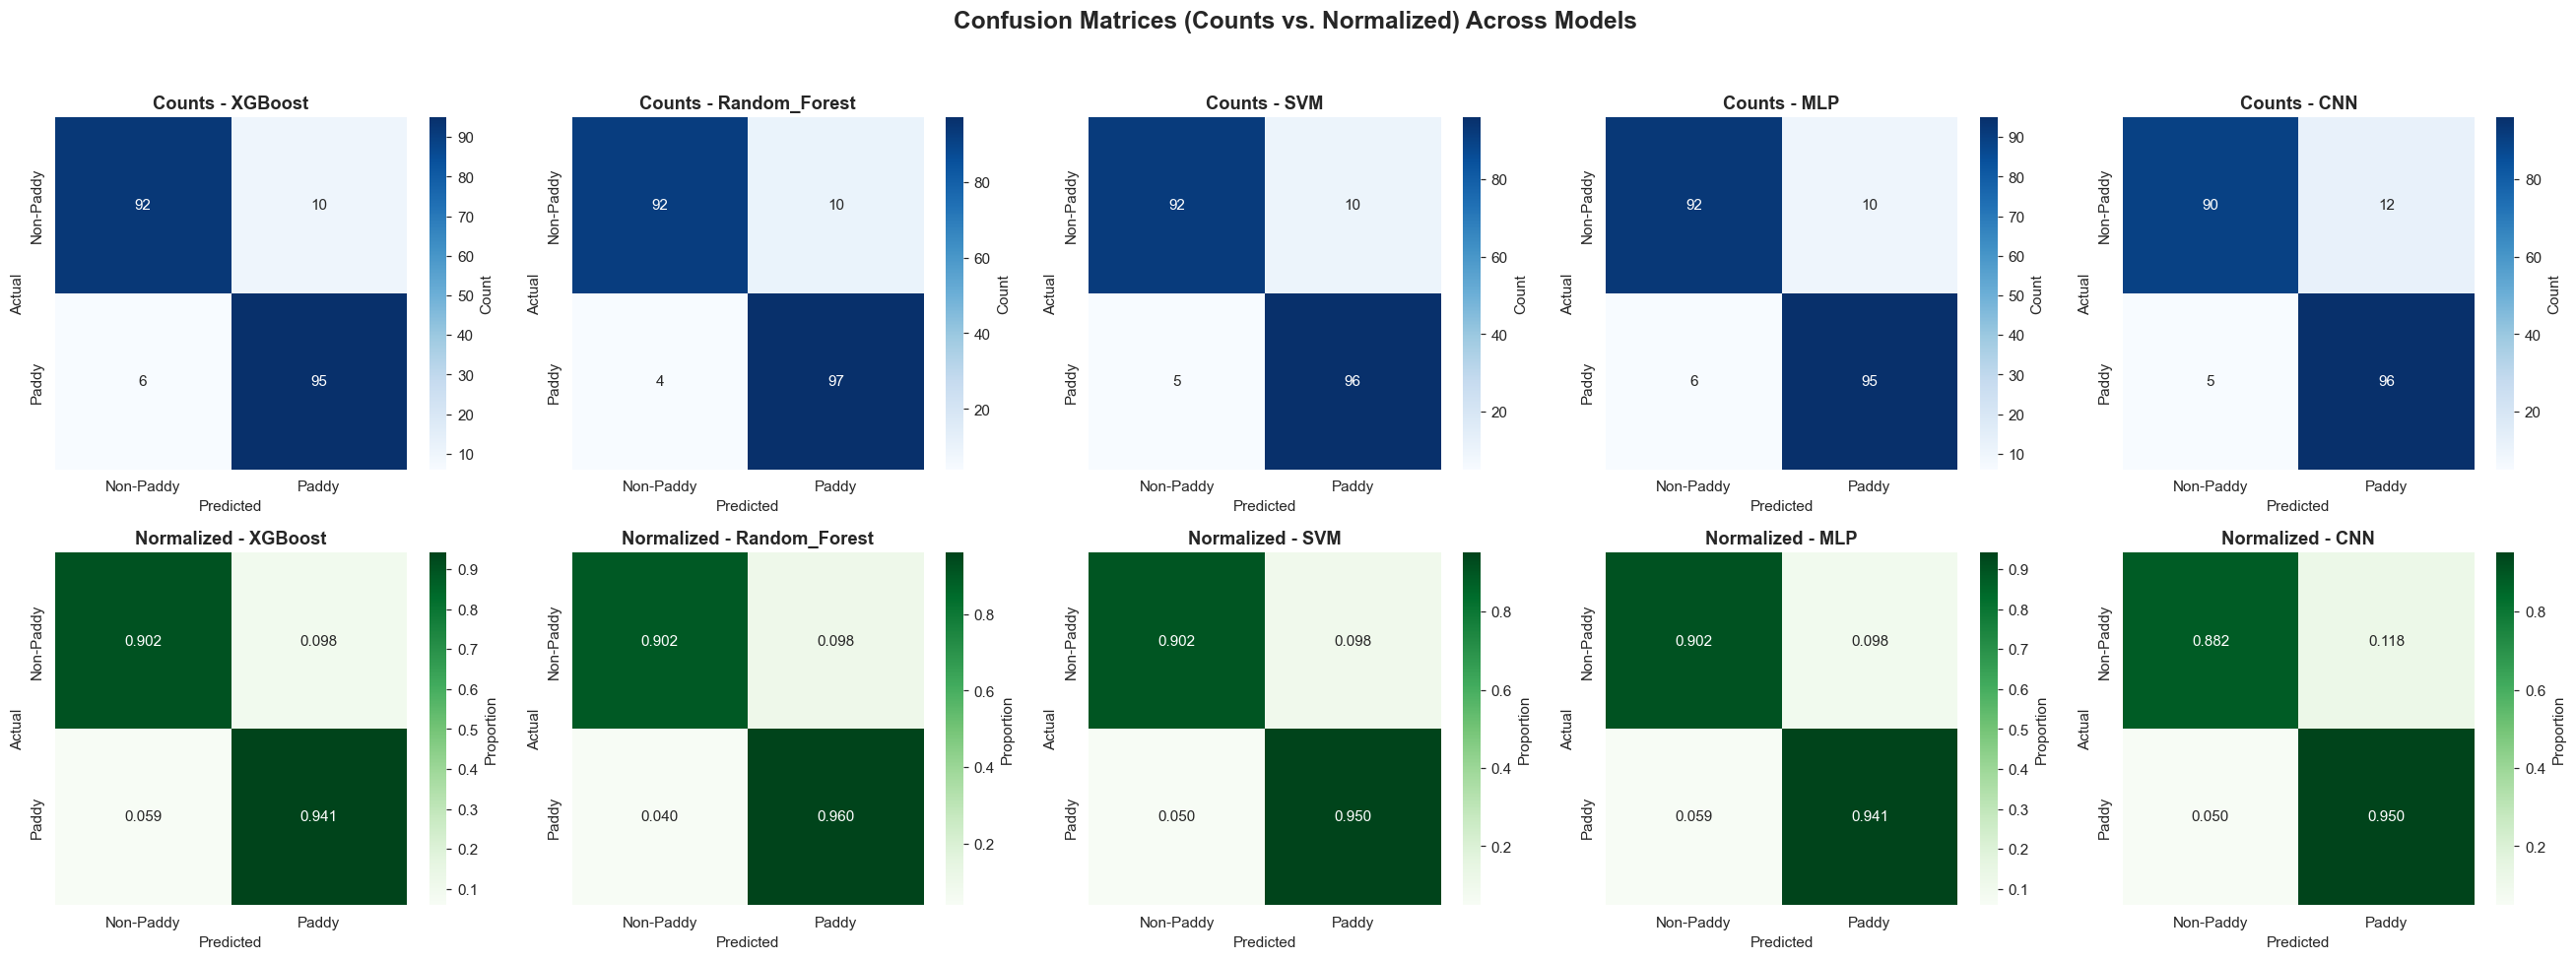

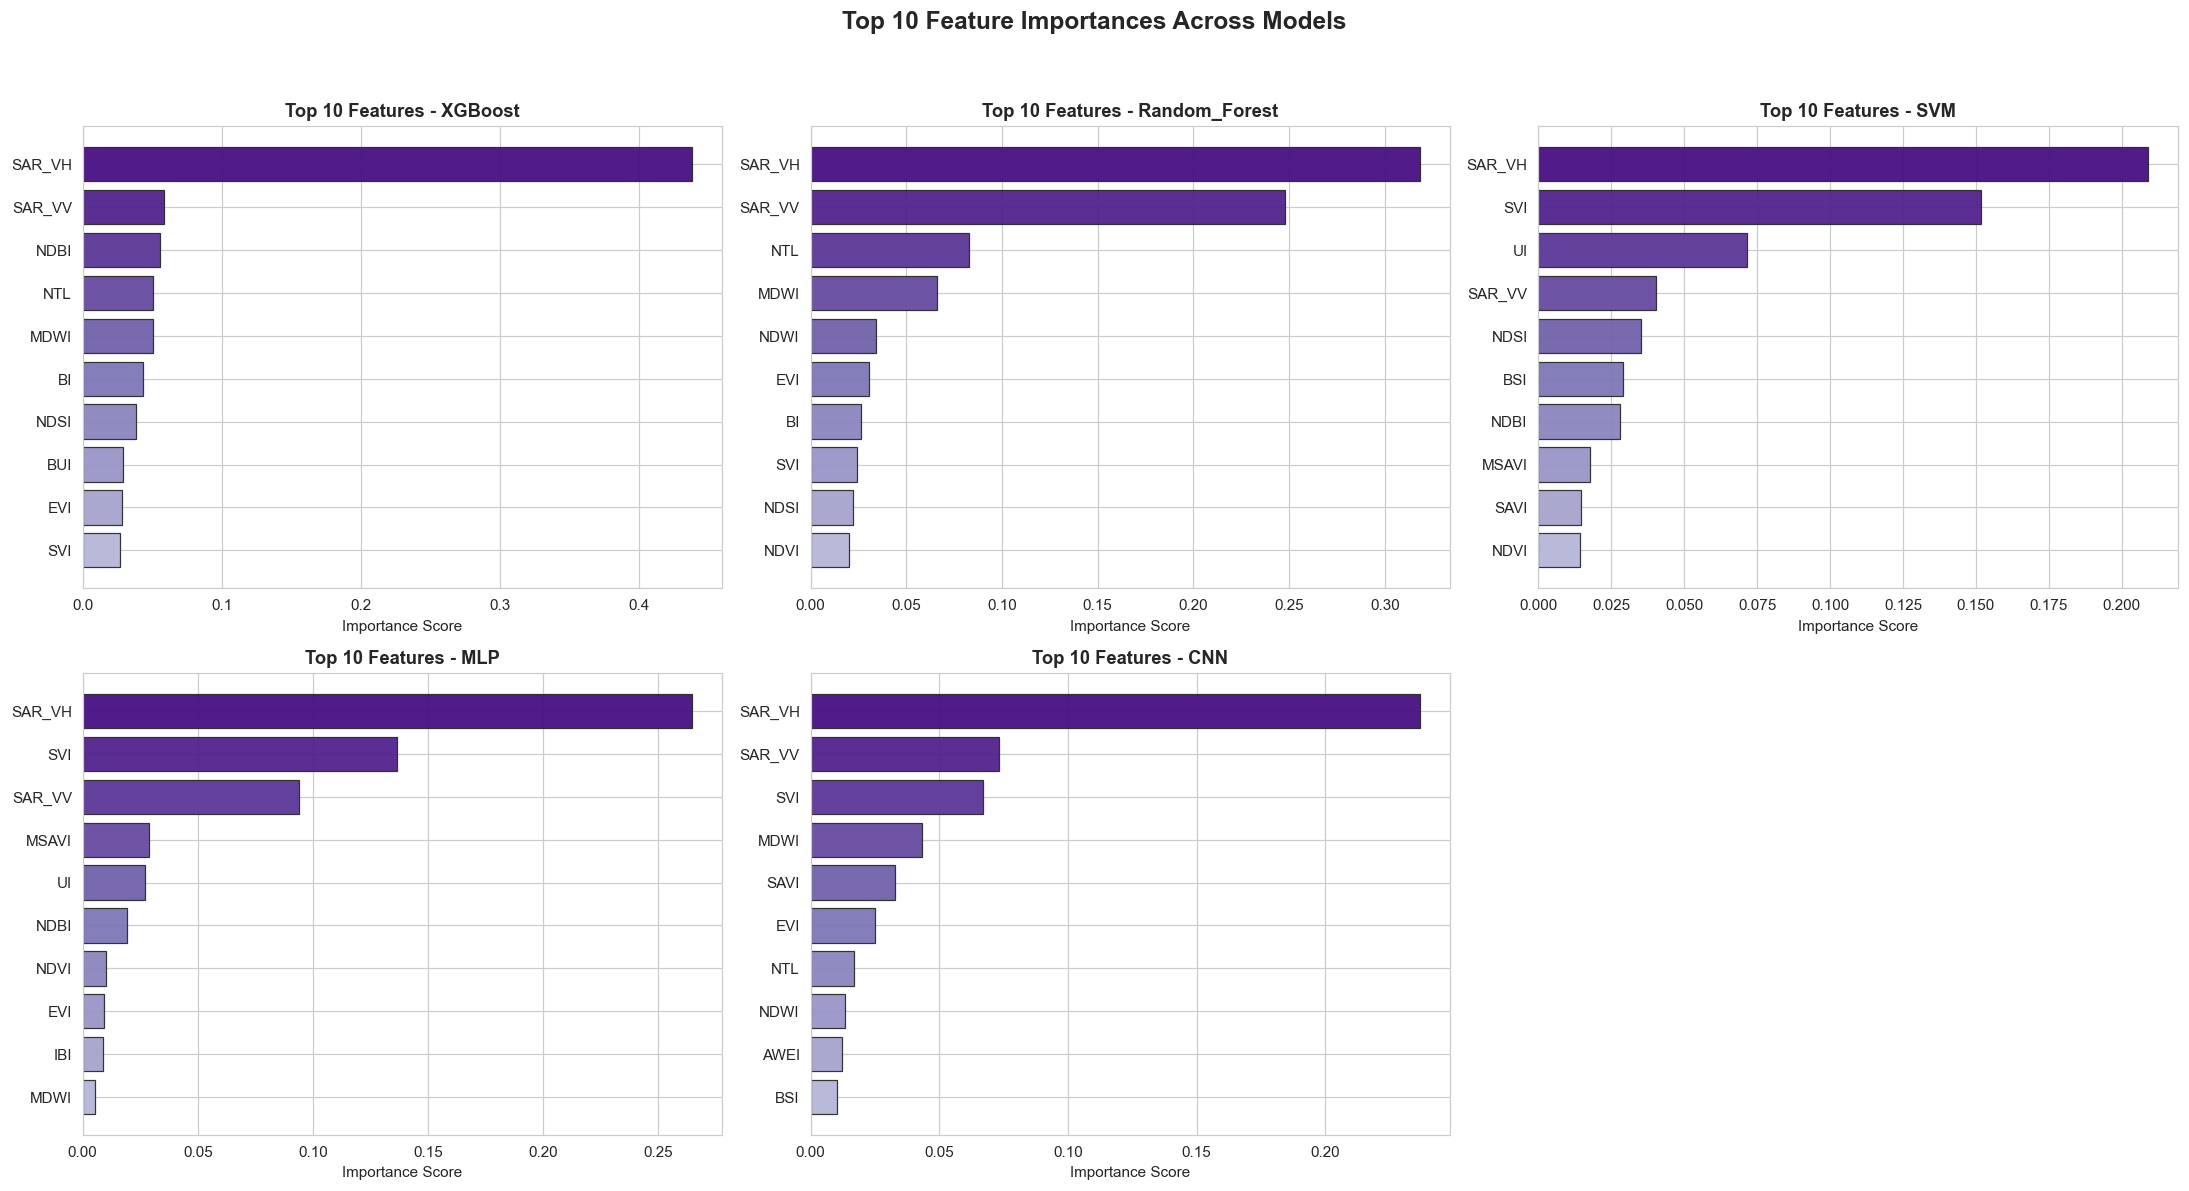

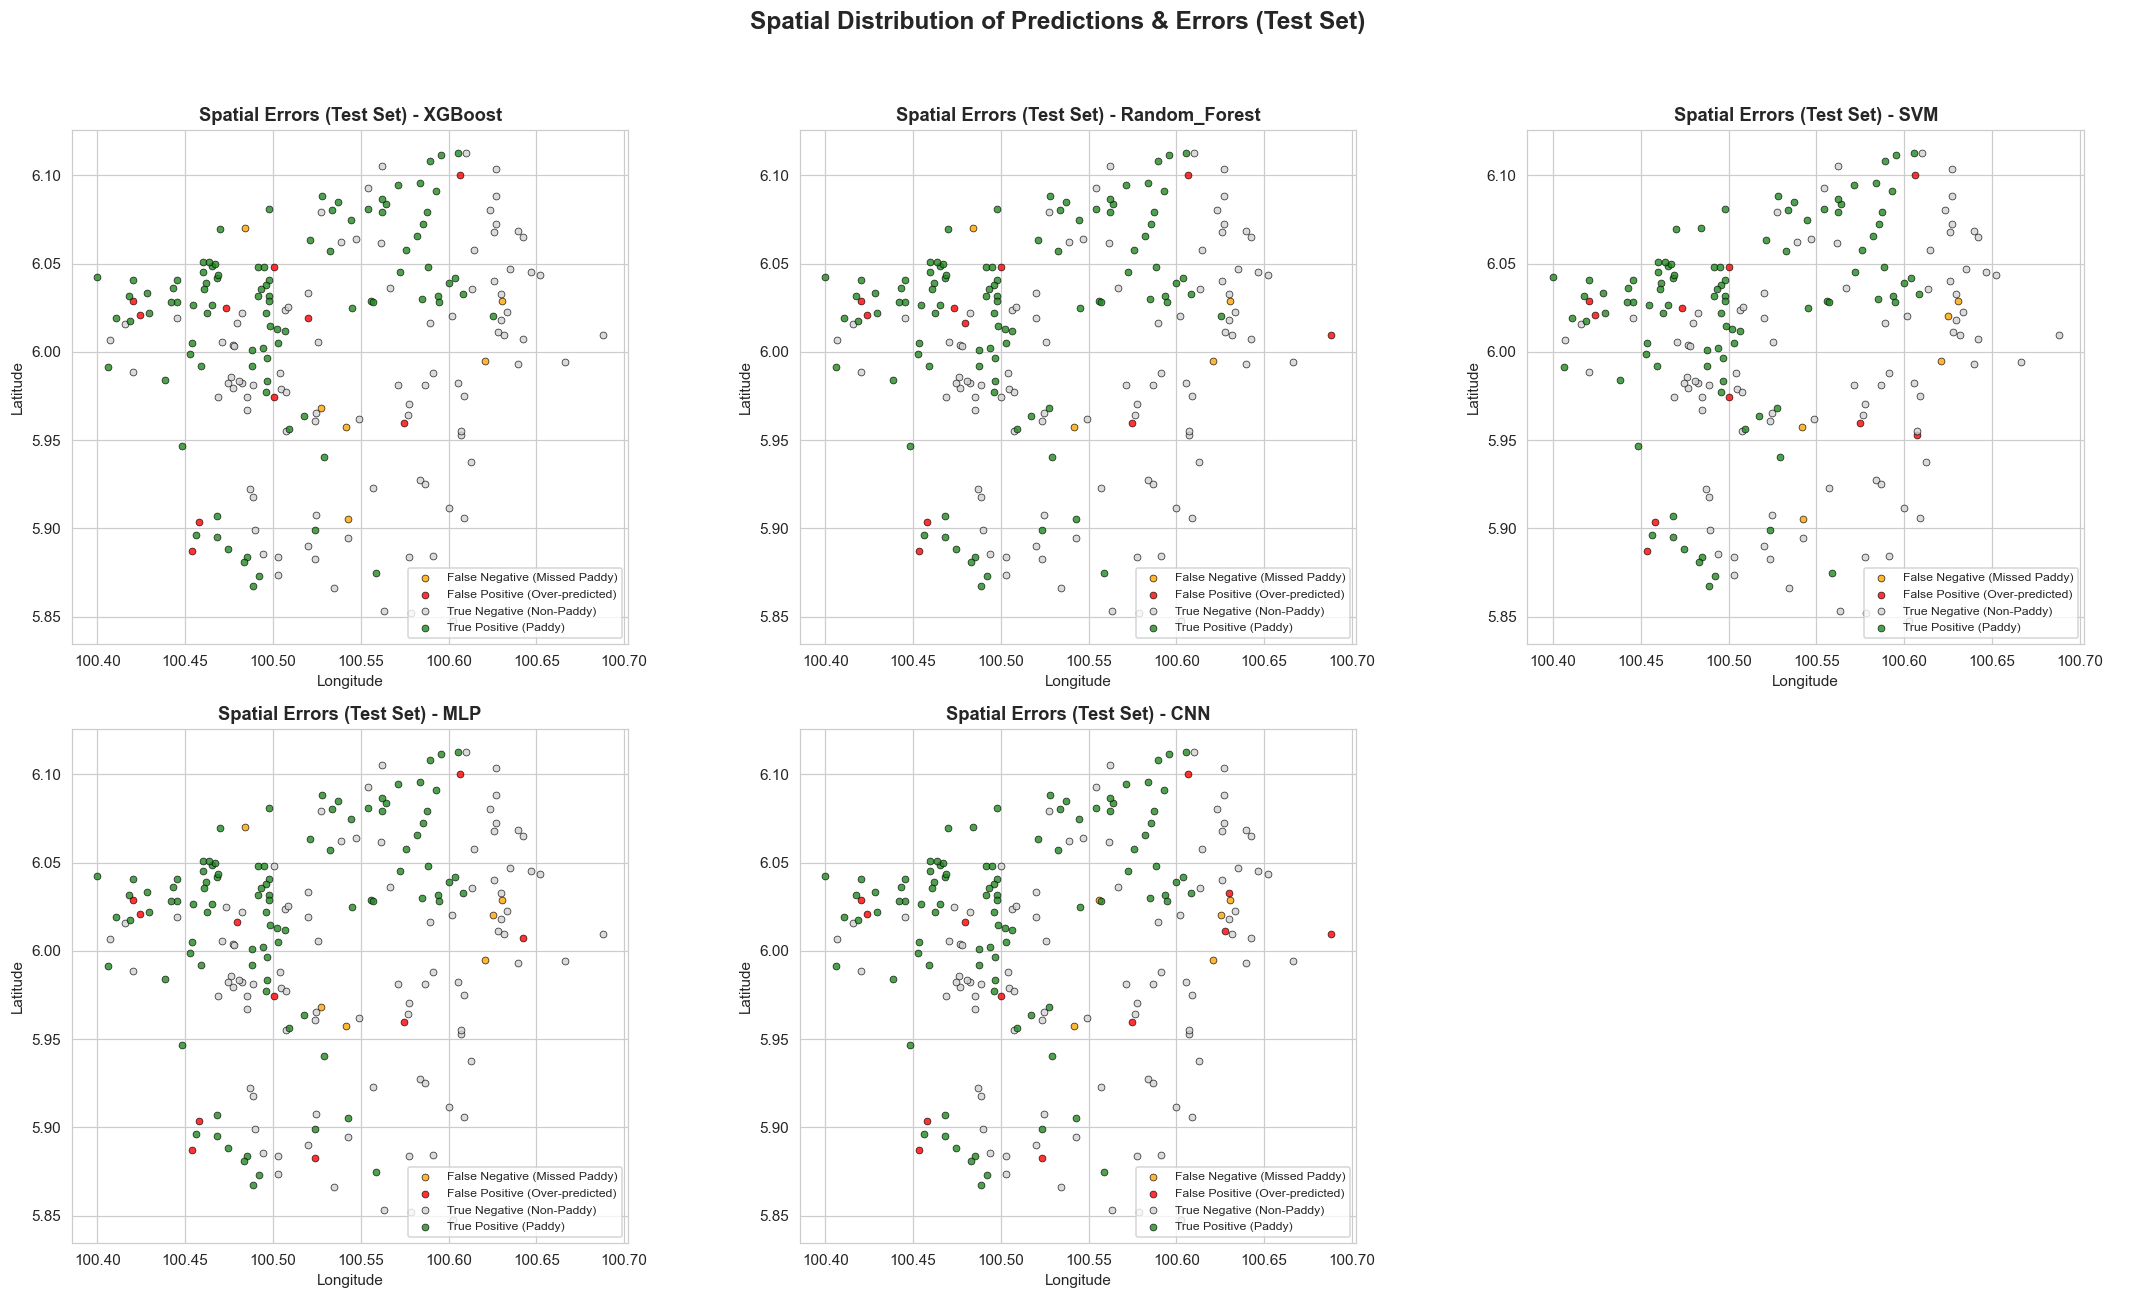

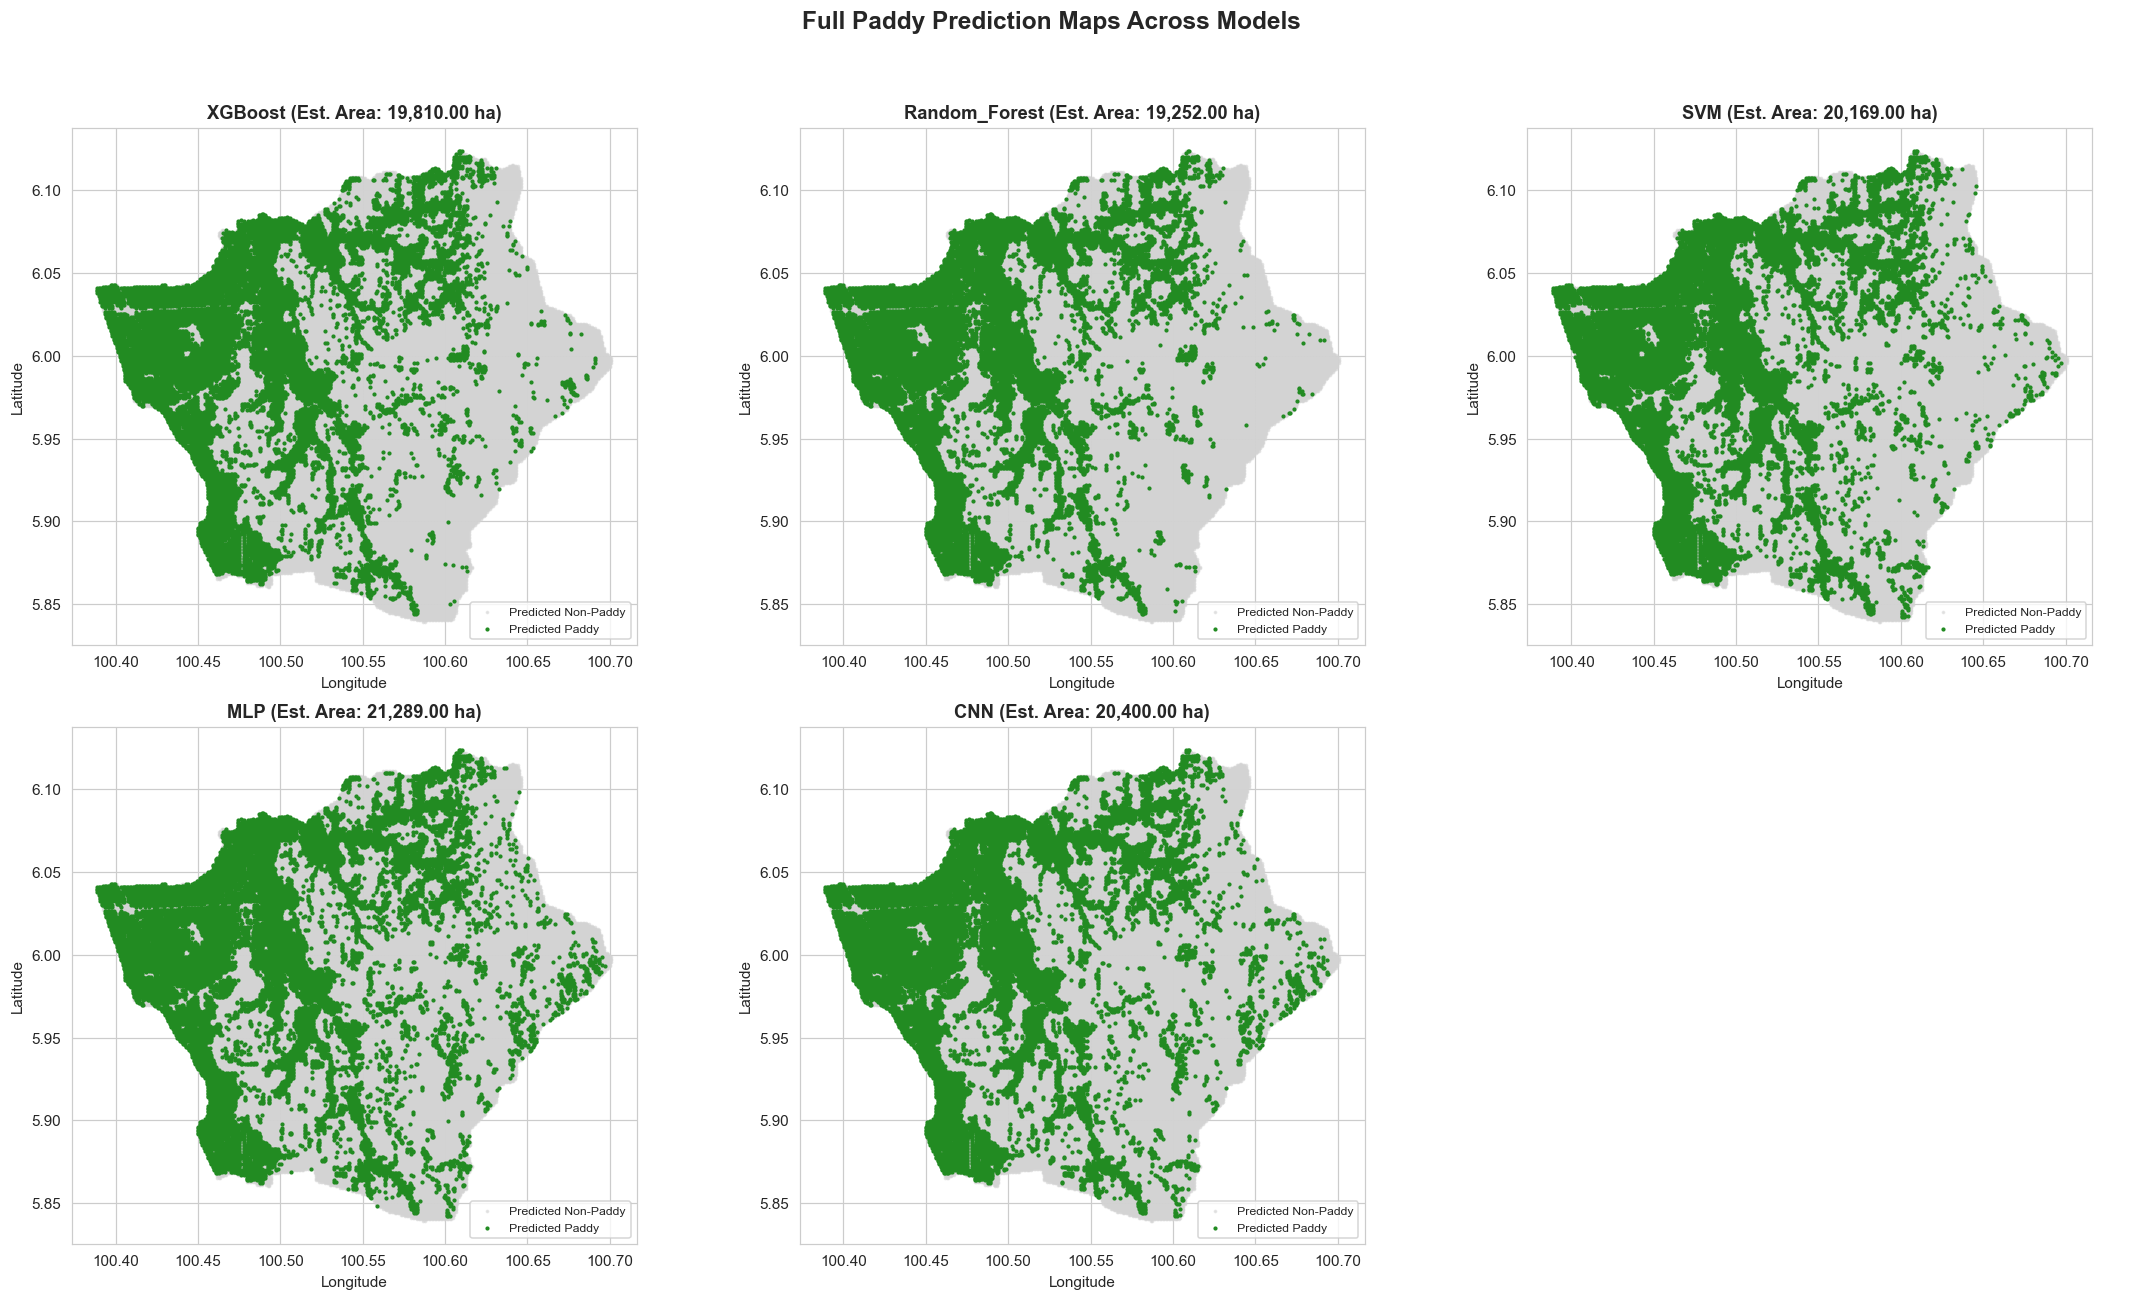

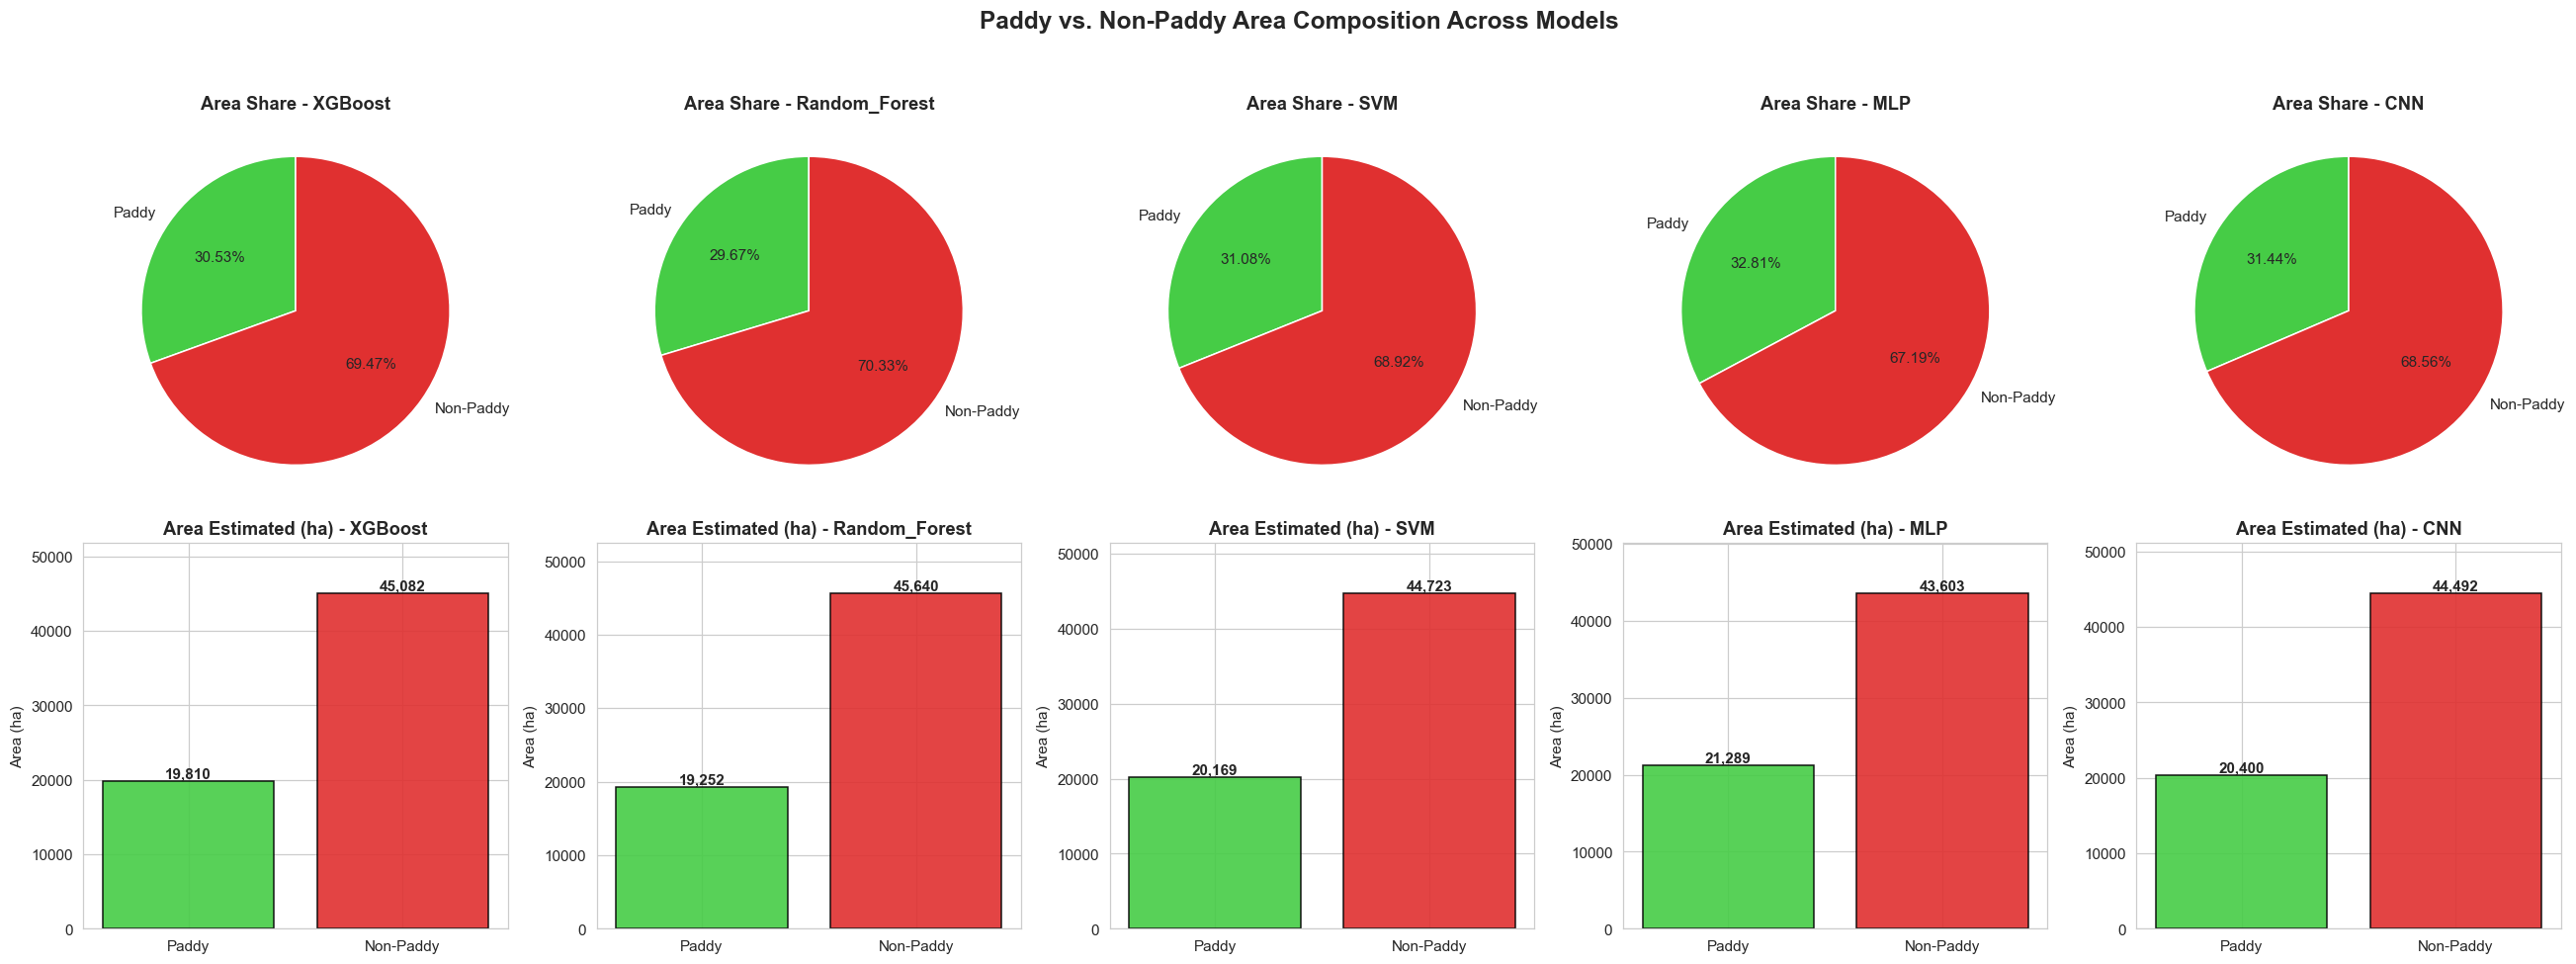


--- Model Performance Comparison (Hold-out Test Set) ---
               Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
Model                                                                
XGBoost          0.9212     0.9048  0.9406    0.9223   0.9753  0.9722
Random_Forest    0.9310     0.9065  0.9604    0.9327   0.9727  0.9723
SVM              0.9261     0.9057  0.9505    0.9275   0.9765  0.9724
MLP              0.9212     0.9048  0.9406    0.9223   0.9842  0.9836
CNN              0.9163     0.8889  0.9505    0.9187   0.9770  0.9764

--- Total Estimated Paddy Area Comparison ---
               Estimated Paddy Area (ha)
XGBoost                          19810.0
Random_Forest                    19252.0
SVM                              20169.0
MLP                              21289.0
CNN                              20400.0

All models trained, evaluated, rasterized, and mapped.


In [5]:
# ============================================================
# STEP (4): MODEL DEVELOPMENT
# ============================================================

# ============================================================
# 4.1 FILE PATHS & SETUP
# ============================================================
# Define the training dataset containing ground truth matched with satellite data
TRAIN_FILE = training.copy()
# Define the full cleaned study area dataset to be used for final prediction mapping
TEST_FILE   = df_cleaned.copy()

# Set the exact column name representing the target variable (paddy vs non-paddy)
LABEL_COLUMN = "paddy_label"
# Define variables mapping to the longitude and latitude column headers
LON_COLUMN, LAT_COLUMN = "LONGITUDE", "LATITUDE"
# Define the spatial resolution/pixel size of the satellite imagery (100x100 meters)
CELL_SIZE = 100.0
# Calculate half the cell size, used later for precise raster coordinate alignment
HALF_CELL = CELL_SIZE / 2.0
# Define the block size in degrees (~2 km) for grouping data in Spatial Cross-Validation
BLOCK_SIZE_DEG = 0.02   

# ============================================================
# 4.2 DATA LOADING & PREPROCESSING
# ============================================================
# Load the matched training dataset into a pandas DataFrame
train_df = TRAIN_FILE
# Load the full study area dataset into a pandas DataFrame
test_df  = TEST_FILE

# Define a list of columns containing metadata, spatial coordinates, or legacy artifacts that shouldn't be used as ML features
NON_FEATURE_COLUMNS = [
    LABEL_COLUMN, "NAMA_DAERAH", "KOD_NG", "NG", 'id', 'name', 'code_state', 
    'state', "sample_id", "csv_id", "distance_m", "longitude", "latitude", 
    "lon", "lat", 'LONGITUDE', 'LATITUDE', "geometry", "GEOMETRY", 
    "index_left", "index_right", "Class"
]

# Identify all valid feature columns by selecting everything not in the NON_FEATURE_COLUMNS list
FEATURE_COLUMNS = [c for c in train_df.columns if c not in NON_FEATURE_COLUMNS]

# Loop over every feature column to ensure the data type is numeric
for col in FEATURE_COLUMNS:
    # Convert training data to numeric, replacing any unparseable text with NaN (errors="coerce")
    train_df[col] = pd.to_numeric(train_df[col], errors="coerce")
    # Convert test data to numeric similarly
    test_df[col]  = pd.to_numeric(test_df[col],  errors="coerce")

# Replace any mathematically infinite values (Inf, -Inf) in the training set with standard NaN markers
train_df[FEATURE_COLUMNS] = train_df[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)
# Replace infinite values in the test set with NaN markers
test_df[FEATURE_COLUMNS]  = test_df[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)

# Calculate the number of unique values for each feature in the training dataset
n_unique = train_df[FEATURE_COLUMNS].nunique()
# Identify "constant features" (features with 1 or fewer unique values) because they provide zero predictive power
constant_features = [c for c in FEATURE_COLUMNS if n_unique[c] <= 1]
# Update the FEATURE_COLUMNS list to exclude these constant, useless variables
FEATURE_COLUMNS = [c for c in FEATURE_COLUMNS if c not in constant_features]

# ============================================================
# 4.3 TRAIN / TEST SPLIT
# ============================================================
# Extract the finalized feature matrix (X) from the training dataframe
X_all = train_df[FEATURE_COLUMNS].copy()
# Extract the target label vector (y), ensuring it's cast to integer type (0 or 1)
y_all = train_df[LABEL_COLUMN].astype(int)

# Extract the raw longitude coordinates for spatial cross-validation blocking
lon_all = train_df[LON_COLUMN].values
# Extract the raw latitude coordinates for spatial cross-validation blocking
lat_all = train_df[LAT_COLUMN].values

# Split the dataset into 80% training data and 20% testing/validation data
# Use stratify=y_all to ensure the paddy/non-paddy ratio is maintained in both splits
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=42
)

# ============================================================
# 4.4 MASTER MODEL CONFIGURATIONS & EXECUTION LOOP
# ============================================================
# Store the total number of features to define the input shape for the neural network
num_features = len(FEATURE_COLUMNS)

# Define a function to construct and compile a 1D Convolutional Neural Network (CNN) architecture
def create_cnn(filters=32, kernel_size=3, dense_units=32, dropout_rate=0.2, learning_rate=0.001):
    # Initialize a Sequential model (a linear stack of layers)
    model = Sequential()
    # Define the input layer shape based on the number of features
    model.add(Input(shape=(num_features,)))
    # Reshape the flat 1D input into a 2D format expected by Conv1D (features, channels)
    model.add(Reshape((num_features, 1))) 
    # Add a 1D Convolutional layer to detect localized patterns across the feature array
    model.add(Conv1D(filters=filters, kernel_size=kernel_size, activation='relu'))
    # Add a MaxPooling layer to downsample the output and reduce computational complexity
    model.add(MaxPooling1D(pool_size=2))
    # Flatten the 3D tensor back into a 1D vector to feed into fully connected layers
    model.add(Flatten())
    # Add a dense, fully connected hidden layer to learn non-linear combinations
    model.add(Dense(dense_units, activation='relu'))
    # Add a Dropout layer to randomly disable neurons during training, preventing overfitting
    model.add(Dropout(dropout_rate))
    # Add the final output layer with 1 node and a sigmoid activation for binary classification probabilities (0.0 to 1.0)
    model.add(Dense(1, activation='sigmoid'))
    # Compile the model with the Adam optimizer, binary cross-entropy loss, and track accuracy
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='binary_crossentropy', metrics=['accuracy'])
    # Return the compiled model object
    return model

# Define a dictionary containing configurations (Pipelines and Hyperparameter Grids) for all algorithms being evaluated
model_configs = {
    "XGBoost": {
        # Pipeline: First impute missing values with the median, then train the XGBoost classifier
        "pipeline": Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", XGBClassifier(random_state=42, n_jobs=-1, eval_metric="logloss"))]),
        # Grid: Hyperparameters to tune (number of trees, tree depth, learning rate)
        "grid": {"model__n_estimators": [300, 500, 800], "model__max_depth": [3, 5, 10], "model__learning_rate": [0.01, 0.1]}
    },
    "Random_Forest": {
        # Pipeline: Impute missing values with median, then train Random Forest (with balanced class weights)
        "pipeline": Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", RandomForestClassifier(random_state=42, n_jobs=-1, class_weight="balanced"))]),
        # Grid: Hyperparameters (number of trees, max depth, minimum samples needed to split a node)
        "grid": {"model__n_estimators": [300, 500, 800], "model__max_depth": [None, 10, 20], "model__min_samples_split": [2, 5]}
    },
    "SVM": {
        # Pipeline: Impute missing values, strictly standard-scale the data (SVMs are sensitive to scale), then train the SVC
        "pipeline": Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", SVC(probability=True, random_state=42))]),
        # Grid: Hyperparameters (Regularization parameter C, kernel type, kernel coefficient gamma)
        "grid": {"model__C": [0.1, 1, 10], "model__kernel": ["linear", "rbf"], "model__gamma": ["scale", "auto"]}
    },
    "MLP": {
        # Pipeline: Impute, scale (Neural Nets require scaled data), and train Multi-Layer Perceptron
        "pipeline": Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", MLPClassifier(max_iter=500, random_state=42))]),
        # Grid: Hyperparameters (network topology/layers, activation function, initial learning rate)
        "grid": {"model__hidden_layer_sizes": [(64,), (128, 64)], "model__activation": ["relu", "tanh"], "model__learning_rate_init": [0.001, 0.01]}
    },
    "CNN": {
        # Pipeline: Impute, scale, and wrap the Keras CNN function so it interfaces correctly with Scikit-Learn tools
        "pipeline": Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", KerasClassifier(model=create_cnn, verbose=0, random_state=42))]),
        # Grid: Hyperparameters specifically targeting the custom create_cnn function arguments, plus training batch size and epochs
        "grid": {"model__model__filters": [16, 32, 64], "model__model__dense_units": [16, 32, 64], "model__batch_size": [32, 64], "model__epochs": [30, 50]}
    }
}

# Initialize a list to hold performance metrics (Accuracy, F1, etc.) across all models
benchmark_results = []
# Initialize a list to hold Spatial Cross-Validation F1 scores
spatial_cv_results = []
# Initialize dictionaries to hold curve data for ROC, Precision-Recall, and Probability Calibration
roc_data, pr_data, calib_data = {}, {}, {}
# Initialize a dictionary to store total computed paddy area for each model
area_estimates = {}

# Create a spatial block ID for every row by dividing coordinates by the block size, rounding down, and concatenating
# This groups nearby points into the same block to prevent spatial data leakage during cross-validation
block_id = (
    np.floor(lon_all / BLOCK_SIZE_DEG).astype(int).astype(str) + "_" +
    np.floor(lat_all / BLOCK_SIZE_DEG).astype(int).astype(str)
)

# Pre-allocate grouped comparative subplot figures across all 5 models before starting the loop
num_models = len(model_configs)

# 1. Grouped Figure for Confusion Matrices (Row 0: Counts, Row 1: Normalized across all 5 models)
fig_cm, axes_cm = plt.subplots(2, num_models, figsize=(4.8 * num_models, 9))
fig_cm.suptitle("Confusion Matrices (Counts vs. Normalized) Across Models", fontsize=16, fontweight="bold", y=0.98)

# 2. Grouped Figure for Top 10 Feature Importance (2x3 grid for the 5 models)
fig_feat, axes_feat = plt.subplots(2, 3, figsize=(20, 11))
fig_feat.suptitle("Top 10 Feature Importances Across Models", fontsize=16, fontweight="bold", y=0.98)
axes_feat_flat = axes_feat.flatten()
axes_feat_flat[-1].axis("off")  # Hide unused 6th subplot

# 3. Grouped Figure for Spatial Distribution of Errors (2x3 grid for the 5 models)
fig_err, axes_err = plt.subplots(2, 3, figsize=(20, 12))
fig_err.suptitle("Spatial Distribution of Predictions & Errors (Test Set)", fontsize=16, fontweight="bold", y=0.98)
axes_err_flat = axes_err.flatten()
axes_err_flat[-1].axis("off")   # Hide unused 6th subplot

# 4. Grouped Figure for Full Paddy Prediction Maps (2x3 grid for the 5 models)
fig_full, axes_full = plt.subplots(2, 3, figsize=(20, 12))
fig_full.suptitle("Full Paddy Prediction Maps Across Models", fontsize=16, fontweight="bold", y=0.98)
axes_full_flat = axes_full.flatten()
axes_full_flat[-1].axis("off")  # Hide unused 6th subplot

# 5. Grouped Figure for Area Composition (Row 0: Pie Charts, Row 1: Bar Charts across all 5 models)
fig_area, axes_area = plt.subplots(2, num_models, figsize=(4.8 * num_models, 9))
fig_area.suptitle("Paddy vs. Non-Paddy Area Composition Across Models", fontsize=16, fontweight="bold", y=0.98)

# Begin loop to iterate through every model and its configuration defined in the dictionary
for idx, (model_name, config) in enumerate(model_configs.items()):
    # Print a clear header indicating which model is currently being trained
    print(f"\n{'='*50}\nEXECUTING PIPELINE FOR: {model_name}\n{'='*50}")
    
    # Initialize a Randomized Search to find the best hyperparameters via 3-fold cross-validation
    search = RandomizedSearchCV(
        # The ML pipeline to evaluate
        estimator=config["pipeline"], 
        # The dictionary of parameters to randomly sample from
        param_distributions=config["grid"],
        # Number of random parameter combinations to try (limits compute time vs GridSearchCV)
        n_iter=10, 
        # Optimize primarily for F1-score (harmonic mean of precision and recall)
        scoring="f1", 
        # Number of cross-validation folds
        cv=3, 
        random_state=42, n_jobs=-1, verbose=1
    )
    # Execute the hyperparameter search on the training split
    search.fit(X_train, y_train)
    # Extract the absolute best performing model pipeline from the search results
    best_model = search.best_estimator_
    
    # Generate deterministic binary predictions (0 or 1) on the hold-out test set
    test_pred = best_model.predict(X_test)
    # Generate continuous probability predictions (0.0 to 1.0) for the positive class (Paddy)
    test_prob = best_model.predict_proba(X_test)[:, 1]
    
    # Calculate the Area Under the Receiver Operating Characteristic Curve (ROC-AUC)
    roc_auc = roc_auc_score(y_test, test_prob)
    # Calculate the Area Under the Precision-Recall Curve (PR-AUC), which is better for imbalanced data
    pr_auc = average_precision_score(y_test, test_prob)
    
    # Append all core classification metrics to the benchmark list for this model
    benchmark_results.append({
        "Model": model_name, 
        "Accuracy": accuracy_score(y_test, test_pred), 
        "Precision": precision_score(y_test, test_pred, zero_division=0), 
        "Recall": recall_score(y_test, test_pred, zero_division=0), 
        "F1-Score": f1_score(y_test, test_pred, zero_division=0), 
        "ROC-AUC": roc_auc, "PR-AUC": pr_auc
    })
    
    # Calculate and store False Positive Rates and True Positive Rates for ROC curve plotting later
    roc_data[model_name] = (*roc_curve(y_test, test_prob)[:2], roc_auc)
    # Calculate and store Precision and Recall arrays for PR curve plotting later
    pr_data[model_name] = (*precision_recall_curve(y_test, test_prob)[:2], pr_auc)
    # Calculate and store true fractions and predicted probabilities for the calibration curve
    calib_data[model_name] = calibration_curve(y_test, test_prob, n_bins=10, strategy="uniform")
    
    # Generate an absolute count Confusion Matrix
    cm = confusion_matrix(y_test, test_pred)
    # Generate a row-normalized Confusion Matrix to show True Positive / True Negative percentages
    cm_norm = confusion_matrix(y_test, test_pred, normalize="true")
    # Plot the raw counts matrix as a heatmap with a blue color scale in the model's assigned column (Row 0)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes_cm[0, idx], cbar_kws={"label": "Count"},
                xticklabels=["Non-Paddy", "Paddy"], yticklabels=["Non-Paddy", "Paddy"])
    # Set the title for the raw counts subplot
    axes_cm[0, idx].set_title(f"Counts - {model_name}", fontweight="bold")
    axes_cm[0, idx].set_xlabel("Predicted")
    axes_cm[0, idx].set_ylabel("Actual")
    # Plot the normalized matrix as a heatmap with a green color scale in the model's assigned column (Row 1)
    sns.heatmap(cm_norm, annot=True, fmt=".3f", cmap="Greens", ax=axes_cm[1, idx], cbar_kws={"label": "Proportion"},
                xticklabels=["Non-Paddy", "Paddy"], yticklabels=["Non-Paddy", "Paddy"])
    # Set the title for the normalized subplot
    axes_cm[1, idx].set_title(f"Normalized - {model_name}", fontweight="bold")
    axes_cm[1, idx].set_xlabel("Predicted")
    axes_cm[1, idx].set_ylabel("Actual")

    # Extract the raw model object from the final step of the pipeline
    model_obj = best_model.named_steps["model"]
    # Check if the model has an inherent 'feature_importances_' attribute (like Random Forest or XGBoost)
    if hasattr(model_obj, "feature_importances_"):
        # Map the internal feature importances to their respective column names
        importance = pd.DataFrame({"feature": FEATURE_COLUMNS, "importance": model_obj.feature_importances_})
    # If the model does not have native feature importances (like SVM, MLP, CNN)
    else:
        # Use permutation importance: randomly shuffle features and measure how much the F1 score drops
        perm = permutation_importance(best_model, X_test, y_test, scoring='f1', n_repeats=5, random_state=42, n_jobs=-1)
        # Map the mean drop in performance as the importance score
        importance = pd.DataFrame({"feature": FEATURE_COLUMNS, "importance": perm.importances_mean})
    
    # Sort features by importance, extract the top 10, and reverse the order so the highest is at the top of the horizontal bar chart
    top20 = importance.sort_values("importance", ascending=False).head(10).iloc[::-1]
    # Generate a smooth color gradient from light (bottom bar) to rich dark (top bar)
    bar_colors = plt.cm.Purples(np.linspace(0.40, 0.95, len(top20)))
    # Plot a horizontal bar chart of the top features onto the model's assigned subplot in the grouped feature figure
    #axes_feat_flat[idx].barh(top20["feature"], top20["importance"], color="#7f0ec0", edgecolor="black", alpha=0.85)
    # Plot a horizontal bar chart of the top features onto the model's assigned subplot in the grouped feature figure
    axes_feat_flat[idx].barh(top20["feature"], top20["importance"], color=bar_colors, edgecolor="#2b2b2b", linewidth=0.8, alpha=0.95)
    # Set the title for the feature importance chart
    axes_feat_flat[idx].set_title(f"Top 10 Features - {model_name}", fontweight="bold")
    axes_feat_flat[idx].set_xlabel("Importance Score")
    
    # Print status message indicating the start of Spatial Cross-Validation
    print(f"Running Spatial CV for {model_name}...")
    # Initialize GroupKFold with 5 splits to ensure points in the same spatial block stay in the same fold
    gkf = GroupKFold(n_splits=5)
    # Loop through the train and test indices generated by the grouped splitter
    for tr_idx, te_idx in gkf.split(X_all, y_all, groups=block_id):
        # Create a fresh, untrained copy of the optimal pipeline
        clf = clone(best_model)
        # Train the fresh model on the spatial CV training folds
        clf.fit(X_all.iloc[tr_idx], y_all.iloc[tr_idx])
        # Calculate the F1 score on the spatial CV test fold
        fold_f1 = f1_score(y_all.iloc[te_idx], clf.predict(X_all.iloc[te_idx]), zero_division=0)
        # Append the fold's result to the spatial CV tracking list
        spatial_cv_results.append({"Model": model_name, "F1-Score": fold_f1})

    # Prepare the ultimate deployment model by creating a fresh clone of the optimal pipeline
    deployment_model = clone(best_model)
    # Retrain this model on the ENTIRE training dataset (train + test split combined) to maximize learning
    deployment_model.fit(X_all, y_all)
    
    # Create a copy of the massive full-study-area dataset to hold the final predictions
    prediction_df = test_df.copy()
    # Extract just the features from the full dataset for the model to predict on
    X_prediction = prediction_df[FEATURE_COLUMNS].copy()
    # Run the deployment model to predict binary classes (0 or 1) for the entire study area
    prediction_df["prediction"] = deployment_model.predict(X_prediction)
    # Run the deployment model to predict the probabilities of the positive class
    prediction_df["probability"] = deployment_model.predict_proba(X_prediction)[:, 1]
    
    # Count how many total pixels were classified as Paddy (1) vs Non-Paddy (0)
    class_counts = prediction_df["prediction"].value_counts()
    # Calculate the total paddy area in hectares: (pixel count * pixel area in m²) / 10,000 m² per ha
    area_paddy = class_counts.get(1, 0) * ((CELL_SIZE * CELL_SIZE) / 10000)
    # Calculate the total non-paddy area in hectares
    area_nonpaddy = class_counts.get(0, 0) * ((CELL_SIZE * CELL_SIZE) / 10000)
    # Store the calculated paddy area for this specific model in the dictionary
    area_estimates[model_name] = area_paddy
    
    # Print the estimated total area for Paddy to the console
    print(f"{model_name} Estimated Paddy Area: {area_paddy:,.2f} ha")
    # Print the estimated total area for Non-Paddy to the console
    print(f"{model_name} Estimated Non-Paddy Area: {area_nonpaddy:,.2f} ha")
    
    # Convert the prediction dataframe back into a spatial GeoDataFrame using its coordinates
    prediction_gdf = gpd.GeoDataFrame(
        prediction_df, geometry=gpd.points_from_xy(prediction_df[LON_COLUMN], prediction_df[LAT_COLUMN]), crs="EPSG:4326"
    )
    
    # Reproject the GeoDataFrame to the metric CRS (EPSG:3375) required for accurate raster creation
    gdf_projected = prediction_gdf.to_crs("EPSG:3375")
    # Calculate the outermost geographic bounds (Bounding Box) of the predicted data
    min_x, min_y, max_x, max_y = gdf_projected.total_bounds
    # Compute the required raster width (columns) and height (rows) based on bounds and cell size
    width, height = int(np.round((max_x - min_x) / CELL_SIZE)) + 1, int(np.round((max_y - min_y) / CELL_SIZE)) + 1
    # Create the affine transformation matrix tying raster pixels to real-world coordinates
    transform = from_origin(min_x - HALF_CELL, max_y + HALF_CELL, CELL_SIZE, CELL_SIZE)
    
    # Generate an iterator pairing each point geometry with its predicted integer class (0 or 1)
    shapes = ((geom, val) for geom, val in zip(gdf_projected.geometry, gdf_projected["prediction"].astype(np.uint8)))
    # Rasterize the vector points into a 2D numpy array grid, filling empty space with 255 (NoData)
    raster = rasterize(shapes=shapes, out_shape=(height, width), transform=transform, fill=255, dtype=np.uint8)
    
    # Create a temporary DataFrame comparing true labels vs model predictions on the 20% test set
    test_results = pd.DataFrame({
        'Actual': y_test, 'Predicted': test_pred,
        LON_COLUMN: train_df.loc[X_test.index, LON_COLUMN], LAT_COLUMN: train_df.loc[X_test.index, LAT_COLUMN]
    })
    
    # Define a helper function to categorize the specific type of prediction error
    def categorize_error(row):
        # Correctly identified Paddy
        if row['Actual'] == 1 and row['Predicted'] == 1: return 'True Positive (Paddy)'
        # Correctly identified Non-Paddy
        if row['Actual'] == 0 and row['Predicted'] == 0: return 'True Negative (Non-Paddy)'
        # Incorrectly guessed Paddy (Type I Error)
        if row['Actual'] == 0 and row['Predicted'] == 1: return 'False Positive (Over-predicted)'
        # Incorrectly missed a Paddy field (Type II Error)
        return 'False Negative (Missed Paddy)'

    # Apply the categorization function to create an Error_Type column
    test_results['Error_Type'] = test_results.apply(categorize_error, axis=1)
    # Convert the error analysis dataframe into a spatial GeoDataFrame for mapping
    test_results_gdf = gpd.GeoDataFrame(test_results, geometry=gpd.points_from_xy(test_results[LON_COLUMN], test_results[LAT_COLUMN]), crs="EPSG:4326")

    # Define a custom color dictionary to distinguish the 4 error/success categories clearly
    error_colors = {'True Positive (Paddy)': 'forestgreen', 'True Negative (Non-Paddy)': 'lightgrey', 'False Positive (Over-predicted)': 'red', 'False Negative (Missed Paddy)': 'orange'}
    # Loop over each error category and its associated data points
    for ctype, data in test_results_gdf.groupby('Error_Type'):
        # Plot the spatial points on the model's assigned subplot in the grouped error map figure
        data.plot(ax=axes_err_flat[idx], color=error_colors[ctype], label=ctype, markersize=20, alpha=0.8, edgecolor='k', linewidth=0.5)
    # Add a legend to the bottom right of the subplot
    axes_err_flat[idx].legend(loc='lower right', frameon=True, fontsize=8)
    # Set the map title indicating it displays test set errors for this model
    axes_err_flat[idx].set_title(f"Spatial Errors (Test Set) - {model_name}", fontweight="bold")
    axes_err_flat[idx].set_xlabel("Longitude")
    axes_err_flat[idx].set_ylabel("Latitude")

    # Plot all non-paddy predictions as light grey dots in the background of the model's assigned full prediction subplot
    prediction_gdf[prediction_gdf['prediction'] == 0].plot(ax=axes_full_flat[idx], color='lightgrey', markersize=2, label='Predicted Non-Paddy', alpha=0.5)
    # Plot all paddy predictions as prominent green dots in the foreground of the model's assigned full prediction subplot
    prediction_gdf[prediction_gdf['prediction'] == 1].plot(ax=axes_full_flat[idx], color='forestgreen', markersize=3, label='Predicted Paddy')
    # Add the legend to the subplot
    axes_full_flat[idx].legend(loc='lower right', frameon=True, fontsize=8)
    # Set the title, explicitly stating the estimated area computed earlier
    axes_full_flat[idx].set_title(f"{model_name} (Est. Area: {area_paddy:,.2f} ha)", fontweight="bold")
    axes_full_flat[idx].set_xlabel("Longitude")
    axes_full_flat[idx].set_ylabel("Latitude")

    # On the top row of the grouped area composition figure, plot a Pie Chart comparing total Paddy vs Non-Paddy areas
    axes_area[0, idx].pie([area_paddy, area_nonpaddy],
                          labels=["Paddy", "Non-Paddy"],
                          # Display percentages with 2 decimal places
                          autopct="%1.2f%%", startangle=90,
                          # Use green for Paddy and red for Non-Paddy
                          colors=["#46cc46", "#e03030"])
    # Set the title for the pie chart subplot
    axes_area[0, idx].set_title(f"Area Share - {model_name}", fontweight="bold")

    # On the bottom row of the grouped area composition figure, plot a Bar Chart comparing the raw hectare values
    axes_area[1, idx].bar(["Paddy", "Non-Paddy"], [area_paddy, area_nonpaddy],
                          color=["#46cc46", "#e03030"], edgecolor="black", alpha=0.9)
    # Set the y-axis label to indicate units are in hectares
    axes_area[1, idx].set_ylabel("Area (ha)")
    # Set the title for the bar chart subplot
    axes_area[1, idx].set_title(f"Area Estimated (ha) - {model_name}", fontweight="bold")
    axes_area[1, idx].margins(y=0.15)
    # Loop over the bar values to annotate the exact numerical area above each bar
    for i, v in enumerate([area_paddy, area_nonpaddy]):
        # Place text at the center (x-axis) and just above the bar top (y-axis), formatted with commas
        axes_area[1, idx].text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontweight="bold")

# Finalize padding, save, and display each of the 5 grouped comparative figures
fig_cm.tight_layout(rect=[0, 0, 1, 0.95])
fig_feat.tight_layout(rect=[0, 0, 1, 0.95])
fig_err.tight_layout(rect=[0, 0, 1, 0.95])
fig_full.tight_layout(rect=[0, 0, 1, 0.95])
fig_area.tight_layout(rect=[0, 0, 1, 0.95])

#Display all the generated figures in a single interactive window for visual inspection
plt.show()

# Convert the list of dictionaries containing benchmark metrics into a pandas DataFrame and set the 'Model' name as the row index
metrics_df = pd.DataFrame(benchmark_results).set_index("Model")
# Print a sub-header indicating the upcoming display of the model performance metrics on the test dataset
print("\n--- Model Performance Comparison (Hold-out Test Set) ---")
# Round all metric values to 4 decimal places and print the entire DataFrame as a formatted string to the console
print(metrics_df.round(4).to_string())

# Create a new DataFrame from the area_estimates dictionary, orienting the model keys as rows and naming the output column
area_df = pd.DataFrame.from_dict(area_estimates, orient='index', columns=['Estimated Paddy Area (ha)'])
# Print a sub-header for the estimated area comparison section
print("\n--- Total Estimated Paddy Area Comparison ---")
# Round the area estimations to 2 decimal places and print the DataFrame to the console
print(area_df.round(2).to_string())

# Print a final confirmation message displaying the directory where all the generated outputs (models, CSVs, TIFFs, PNGs) are located
print(f"\nAll models trained, evaluated, rasterized, and mapped.")

---

#### <h2 style="text-align: center;">**5.0 FINDINGS AND DISCUSSION**</h2>

---

This section evaluates the empirical results obtained from the five machine learning and deep learning architectures; **XGBoost**, **Random Forest (RF)**, **Support Vector Machine (SVM)**, **Multilayer Perceptron (MLP)**, and **1D Convolutional Neural Network (CNN)** deployed to classify and estimate the total paddy field area in the Pendang district of Kedah. The model outputs are critically discussed in relation to spectral feature importance, spatial error distributions, and official institutional ground-truth benchmarks provided by the **Muda Agricultural Development Authority (MADA)** (**14,052.04 ha**) and **Pihak Berkuasa Tempatan (PBT) Kedah** (**18,462.00 ha**).

---

### **5.1 Model Classification Performance (Confusion Matrix Analysis)**

The predictive accuracy of each algorithm was evaluated on the 20% stratified hold-out test set ($N = 203$ samples, comprising $101$ actual paddy pixels and $102$ actual non-paddy pixels). Table 5.1 summarizes the raw confusion matrix counts, normalized proportions, and derived classification metrics across all five models.

**Table 5.1: Hold-Out Test Set Confusion Matrix & Classification Metrics Across Models**

| Model | True Negative ($TN$) | False Positive ($FP$) | False Negative ($FN$) | True Positive ($TP$) | Specificity ($TN$ Rate) | Recall ($TP$ Rate) | Precision | Overall Accuracy | F1-Score |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Random Forest** | 92 | 10 | **4** | **97** | 90.20% | **96.04%** | **90.65%** | **93.10%** | **93.27%** |
| **SVM** | 92 | 10 | 5 | 96 | 90.20% | 95.05% | 90.57% | 92.61% | 92.75% |
| **XGBoost** | 92 | 10 | 6 | 95 | 90.20% | 94.06% | 90.48% | 92.12% | 92.23% |
| **MLP** | 92 | 10 | 6 | 95 | 90.20% | 94.06% | 90.48% | 92.12% | 92.23% |
| **CNN** | 90 | 12 | 5 | 96 | 88.24% | 95.05% | 88.89% | 91.63% | 91.87% |

**Key Observations:**
1. **Superior Sensitivity of Random Forest:** **Random Forest** achieved the strongest overall performance on the validation set, recording the highest True Positive rate (**96.0%** or $97/101$ paddy samples correctly identified) and the lowest False Negative count (only $4$ missed paddy parcels), yielding an F1-Score of **93.27%** and an overall accuracy of **93.10%**.

2. **Consistent Non-Paddy Specificity:** Four of the five architectures (**XGBoost**, **Random Forest**, **SVM**, and **MLP**) achieved identical specificity on non-paddy land, correctly classifying **90.2%** ($92/102$) of non-paddy pixels while generating exactly $10$ False Positives (**9.8%**). Conversely, the **1D-CNN** exhibited slightly higher Type I error (over-prediction), misclassifying $12$ non-paddy samples (**11.8%**) as paddy.

3. **Asymmetry Between False Positives and False Negatives:** Across all five algorithms, the False Positive rate ($9.8\%\text{–}11.8\%$) was consistently higher than the False Negative rate ($4.0\%\text{–}5.9\%$). While this high sensitivity ensures that very few active paddy fields are missed, applying a model with a ~10% False Positive rate across a predominantly non-paddy district (~70% non-paddy land) creates a systematic upward bias in total area estimation.

---

### **5.2 Spectral and Radar Feature Importance Analysis**

The comparative feature importance evaluation (derived from native tree split importance for **XGBoost** and **Random Forest**, and F1-based permutation importance for **SVM**, **MLP**, and **CNN**) reveals a strong consensus regarding the physical drivers of paddy classification in Pendang:

* **Dominance of Active Microwave Radar (`SAR_VH` and `SAR_VV`):** Across all five models, Sentinel-1 Synthetic Aperture Radar cross-polarized backscatter (**`SAR_VH`**) emerged as the single most decisive predictor, recording importance scores of approximately **0.44** in XGBoost, **0.32** in Random Forest, **0.26** in MLP, **0.24** in CNN, and **0.21** in SVM. Co-polarized backscatter (**`SAR_VV`**) ranked second in XGBoost, Random Forest (**~0.25**), and CNN (**~0.075**), and third in MLP (**~0.09**). This confirms that C-band radar is superior to optical indices alone for tropical paddy mapping because it penetrates persistent cloud cover and directly captures the double-bounce and volume scattering mechanics of flooded soil transitions and emerging vertical rice stalks.

* **Role of Topographic/Soil Vulnerability (`SVI`) and Moisture Indices (`MDWI`, `NDWI`):** In the non-tree models (**SVM**, **MLP**, and **CNN**), the **Soil Vulnerability Index (`SVI`)** ranked as the second or third most influential variable (importance scores between **0.07** and **0.15**). Because paddy cultivation in Pendang is strictly constrained to flat, low-lying alluvial plains with minimal runoff slope, `SVI` effectively separates lowland granary basins from undulating eastern rubber and oil palm estates. Similarly, **`MDWI`** and **`NDWI`** featured in the top five predictors for Random Forest, XGBoost, and CNN, capturing the standing water signature during the inundated planting phase.

* **Anthropogenic & Built-Up Exclusion (`NTL`, `NDBI`, `UI`, `BI`):** **Night Time Light (`NTL`)** and urban/bare-soil indices (**`NDBI`**, **`UI`**, **`BI`**, **`NDSI`**) consistently ranked within the top six features for XGBoost, Random Forest, and SVM. Rather than detecting rice directly, these variables act as negative masks that allow the algorithms to strip out rural towns, road networks, and residential homesteads interspersed throughout the agricultural corridor.

---

### **5.3 Spatial Distribution of Predictions and Error Mapping**

Visual inspection of the **Spatial Distribution of Errors** (`100.40°E` to `100.70°E` Longitude; `5.85°N` to `6.12°N` Latitude) and the **Full Study Area Prediction Maps** highlights a sharp geographical dichotomy across the Pendang district totaling **64,892.00 hectares** ($64,892$ pixels at $100\text{ m} \times 100\text{ m}$ resolution):

1. **Western Contiguous Granary Corridor (`100.40°E` to `100.52°E`):** All five models exhibit high spatial agreement across the flat western alluvial plain, delineating a dense, uninterrupted green belt of **True Positive** paddy fields. Very few errors occur within the interior of this western block because it falls directly under the intensively irrigated MADA canal network, producing uniform spectral and radar signatures.

2. **Central Transitional Ecotone (`100.50°E` to `100.58°E`):** The majority of **False Positives (red points)** and **False Negatives (orange points)** on the test set occur along the fragmented central boundary where flat paddy plains transition into mixed village orchards (*kampung*), seasonal wetlands, and smallholder tree crops. At a $100\text{ m}$ pixel resolution ($1\text{ ha}$ per pixel), boundary pixels frequently contain a mixture of narrow paddy bunds, drainage ditches, and adjacent scrubland ("mixed pixels"), causing edge-classification ambiguity.

3. **Eastern Uplands and Fringe Catchments (`100.58°E` to `100.70°E`):** While dominated by **True Negative** non-paddy terrain (grey), the models diverge in how aggressively they classify scattered lowland pockets in the northeast and southeast. **Random Forest** ($19,252\text{ ha}$) and **XGBoost** ($19,810\text{ ha}$) produce cleaner, more conservative maps in the eastern sector, whereas **MLP** ($21,289\text{ ha}$) and **CNN** ($20,400\text{ ha}$) classify noticeably denser clusters of isolated green pixels across the eastern border.

---

### **5.4 Comparative Evaluation: Model Predictions vs. MADA & PBT Kedah Ground Truth**

To evaluate real-world deployment reliability, the total paddy hectarage estimated by each algorithm across the **64,892.00 ha** Pendang study area was benchmarked against two official institutional records:
1. **Lembaga Kemajuan Pertanian Muda (MADA):** **14,052.04 ha**
2. **Pihak Berkuasa Tempatan (PBT) Kedah:** **18,462.00 ha**

**Table 5.2: Comparison of Model Area Predictions Against MADA and PBT Kedah Ground Truth**

| Model | Predicted Paddy Area (ha) | Predicted Non-Paddy Area (ha) | Paddy Share (%) | Variance vs. MADA (14,052.04 ha) | % Diff vs. MADA | Variance vs. PBT Kedah (18,462.00 ha) | % Diff vs. PBT Kedah |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Random Forest** | **19,252.00** | 45,640.00 | 29.67% | +5,199.96 ha | +37.00% | **+790.00 ha** | **+4.28%** |
| **XGBoost** | **19,810.00** | 45,082.00 | 30.53% | +5,757.96 ha | +40.98% | +1,348.00 ha | +7.30% |
| **SVM** | **20,169.00** | 44,723.00 | 31.08% | +6,116.96 ha | +43.53% | +1,707.00 ha | +9.25% |
| **CNN** | **20,400.00** | 44,492.00 | 31.44% | +6,347.96 ha | +45.17% | +1,938.00 ha | +10.50% |
| **MLP** | **21,289.00** | 43,603.00 | 32.81% | +7,236.96 ha | +51.50% | +2,827.00 ha | +15.31% |

---

#### **5.4.1 Explaining the Discrepancy Between MADA (14,052.04 ha) and PBT Kedah (18,462.00 ha)**
A critical finding of this study is that all five machine learning models align closely with the **PBT Kedah benchmark (18,462.00 ha)** while exceeding the **MADA benchmark (14,052.04 ha)** by $5,200\text{ to }7,237\text{ ha}$. This divergence is not a model failure; rather, it reflects the fundamental jurisdictional difference between the two government bodies:

* **MADA's Jurisdictional Scope (Granary-Only):** MADA's figure of **14,052.04 ha** strictly measures gazetted *MADA granary blocks* (*kawasan Muda*) situated in the western alluvial plain of Pendang that are serviced by MADA's primary irrigation infrastructure. It excludes independent paddy parcels cultivated outside the formal MADA boundary.

* **PBT Kedah's Jurisdictional Scope (District-Wide Land Use):** PBT Kedah's figure of **18,462.00 ha** accounts for the *entire administrative district of Pendang*, capturing both the western MADA granary tract ($14,052.04\text{ ha}$) **plus** approximately **$4,409.96\text{ ha}$** of non-granary fringe paddy fields (*padi luar jelapang*) cultivated along central and eastern riverine floodplains.

* **Satellite Sensor Perspective:** Because Earth Observation satellites capture wall-to-wall reflectance and radar backscatter across the entire Pendang administrative shapefile regardless of institutional jurisdiction, the machine learning models naturally detect both MADA and non-MADA paddy parcels. Consequently, the **Full Paddy Prediction Maps** clearly show the solid western MADA block alongside the scattered central/eastern non-granary pockets, mirroring PBT Kedah's district-wide inventory.

---

#### **5.4.2 Factors Contributing to Model Over-Estimation Relative to PBT Kedah (+4.28% to +15.31%)**
While the models strongly validate the PBT Kedah baseline, even the most accurate algorithm (**Random Forest** at **19,252.00 ha**) exceeds the PBT figure by **790.00 ha (+4.28%)**, while **MLP** over-estimates by **2,827.00 ha (+15.31%)**. Three technical factors explain this positive bias (over-prediction):

1. **Spatial Resolution Aggregation ($100\text{ m}$ Grid vs. Cadastral Net Planted Area):** The satellite composite was exported and rasterized at a spatial resolution of $100\text{ m} \times 100\text{ m}$ ($1.0\text{ ha}$ per pixel). Official cadastral figures from MADA and PBT deduct internal non-planted farm infrastructure such as bunds (*batas*), farm tracks, irrigation canals, and machinery sheds which typically occupy $5\%\text{ to }8\%$ of gross parcel area. At $100\text{ m}$ resolution, these sub-pixel linear features are absorbed into the surrounding paddy spectral signature, causing the entire $1\text{ ha}$ pixel to be classified as paddy.

2. **Annual Temporal Median Compositing Effects:** Because the input features were derived using a full-year (Jan–Dec 2023) median composite, low-lying riparian wetlands, waterlogged fallow plots, and swampy grasslands in eastern Pendang exhibit similar median `SAR_VH` backscatter and `MDWI` moisture profiles to single-cropped or rain-fed paddy fields.

3. **Algorithmic Decision Boundaries in High-Dimensional Space:** Tree-based ensembles (**Random Forest** at $19,252\text{ ha}$ and **XGBoost** at $19,810\text{ ha}$) partition the feature space using orthogonal splits, allowing them to isolate sharp thresholds in `SAR_VH`, `SAR_VV`, and `NTL` without over-extrapolating. In contrast, continuous function approximators especially **MLP** ($21,289\text{ ha}$) and **CNN** ($20,400\text{ ha}$) rely on smooth activation hyperplanes that are more susceptible to classifying transitional herbaceous pixels in the eastern uplands as positive paddy occurrences.

---

### **5.5 Selection of the Optimal Model for Operational Deployment**

Based on the multi-criteria evaluation combining hold-out validation metrics, spatial error patterns, and alignment with official government records, **Random Forest** (followed closely by **XGBoost**) is selected as the optimal architecture for Pendang paddy area estimation:

* **Highest Classification Fidelity:** **Random Forest** achieved the highest test-set **F1-Score (93.27%)**, **Overall Accuracy (93.10%)**, and **Sensitivity/Recall (96.04%)**, missing only $4$ out of $101$ ground-truth paddy plots.

* **Closest Alignment to Official District Ground Truth:** Its predicted extent of **19,252.00 ha** (representing **29.67%** of Pendang's total landmass) deviates by only **+790.00 ha (+4.28%)** from PBT Kedah's official district-wide paddy area of **18,462.00 ha**, with the minor $4.28\%$ surplus fully explained by the inclusion of sub-pixel farm bunds and irrigation canals within $100\text{ m}$ satellite grids.

* **Robustness of Tree Ensembles:** Both **Random Forest** (**19,252.00 ha**) and **XGBoost** (**19,810.00 ha**, $+7.30\%$ vs. PBT) effectively leveraged the dual-polarization Sentinel-1 radar bands (`SAR_VH` and `SAR_VV`) alongside `NTL` and `MDWI` to suppress false alarms in the eastern non-granary uplands, providing the most realistic spatial baseline for downstream yield and smallholder economic simulations.


STEP 5: YIELD PRODUCTION & ECONOMIC SIMULATION

--- Economic Simulation for XGBoost (Based on 10,000 Farmers) ---
Land Allocation       : 1.9810 ha / farmer
Yield Production      : 9.311 tonnes / farmer
Gross Yield Income    : RM 18,621.40
Input Subsidies       : RM 1,188.60
Total Gross Revenue   : RM 19,810.00
Total Production Cost : RM 10,895.50
Net Profit            : RM 8,914.50
Estimated Zakat (5%)  : RM 445.73

--- Economic Simulation for Random_Forest (Based on 10,000 Farmers) ---
Land Allocation       : 1.9252 ha / farmer
Yield Production      : 9.048 tonnes / farmer
Gross Yield Income    : RM 18,096.88
Input Subsidies       : RM 1,155.12
Total Gross Revenue   : RM 19,252.00
Total Production Cost : RM 10,588.60
Net Profit            : RM 8,663.40
Estimated Zakat (5%)  : RM 433.17

--- Economic Simulation for SVM (Based on 10,000 Farmers) ---
Land Allocation       : 2.0169 ha / farmer
Yield Production      : 9.479 tonnes / farmer
Gross Yield Income    : RM 18,958.86
Input Subsi

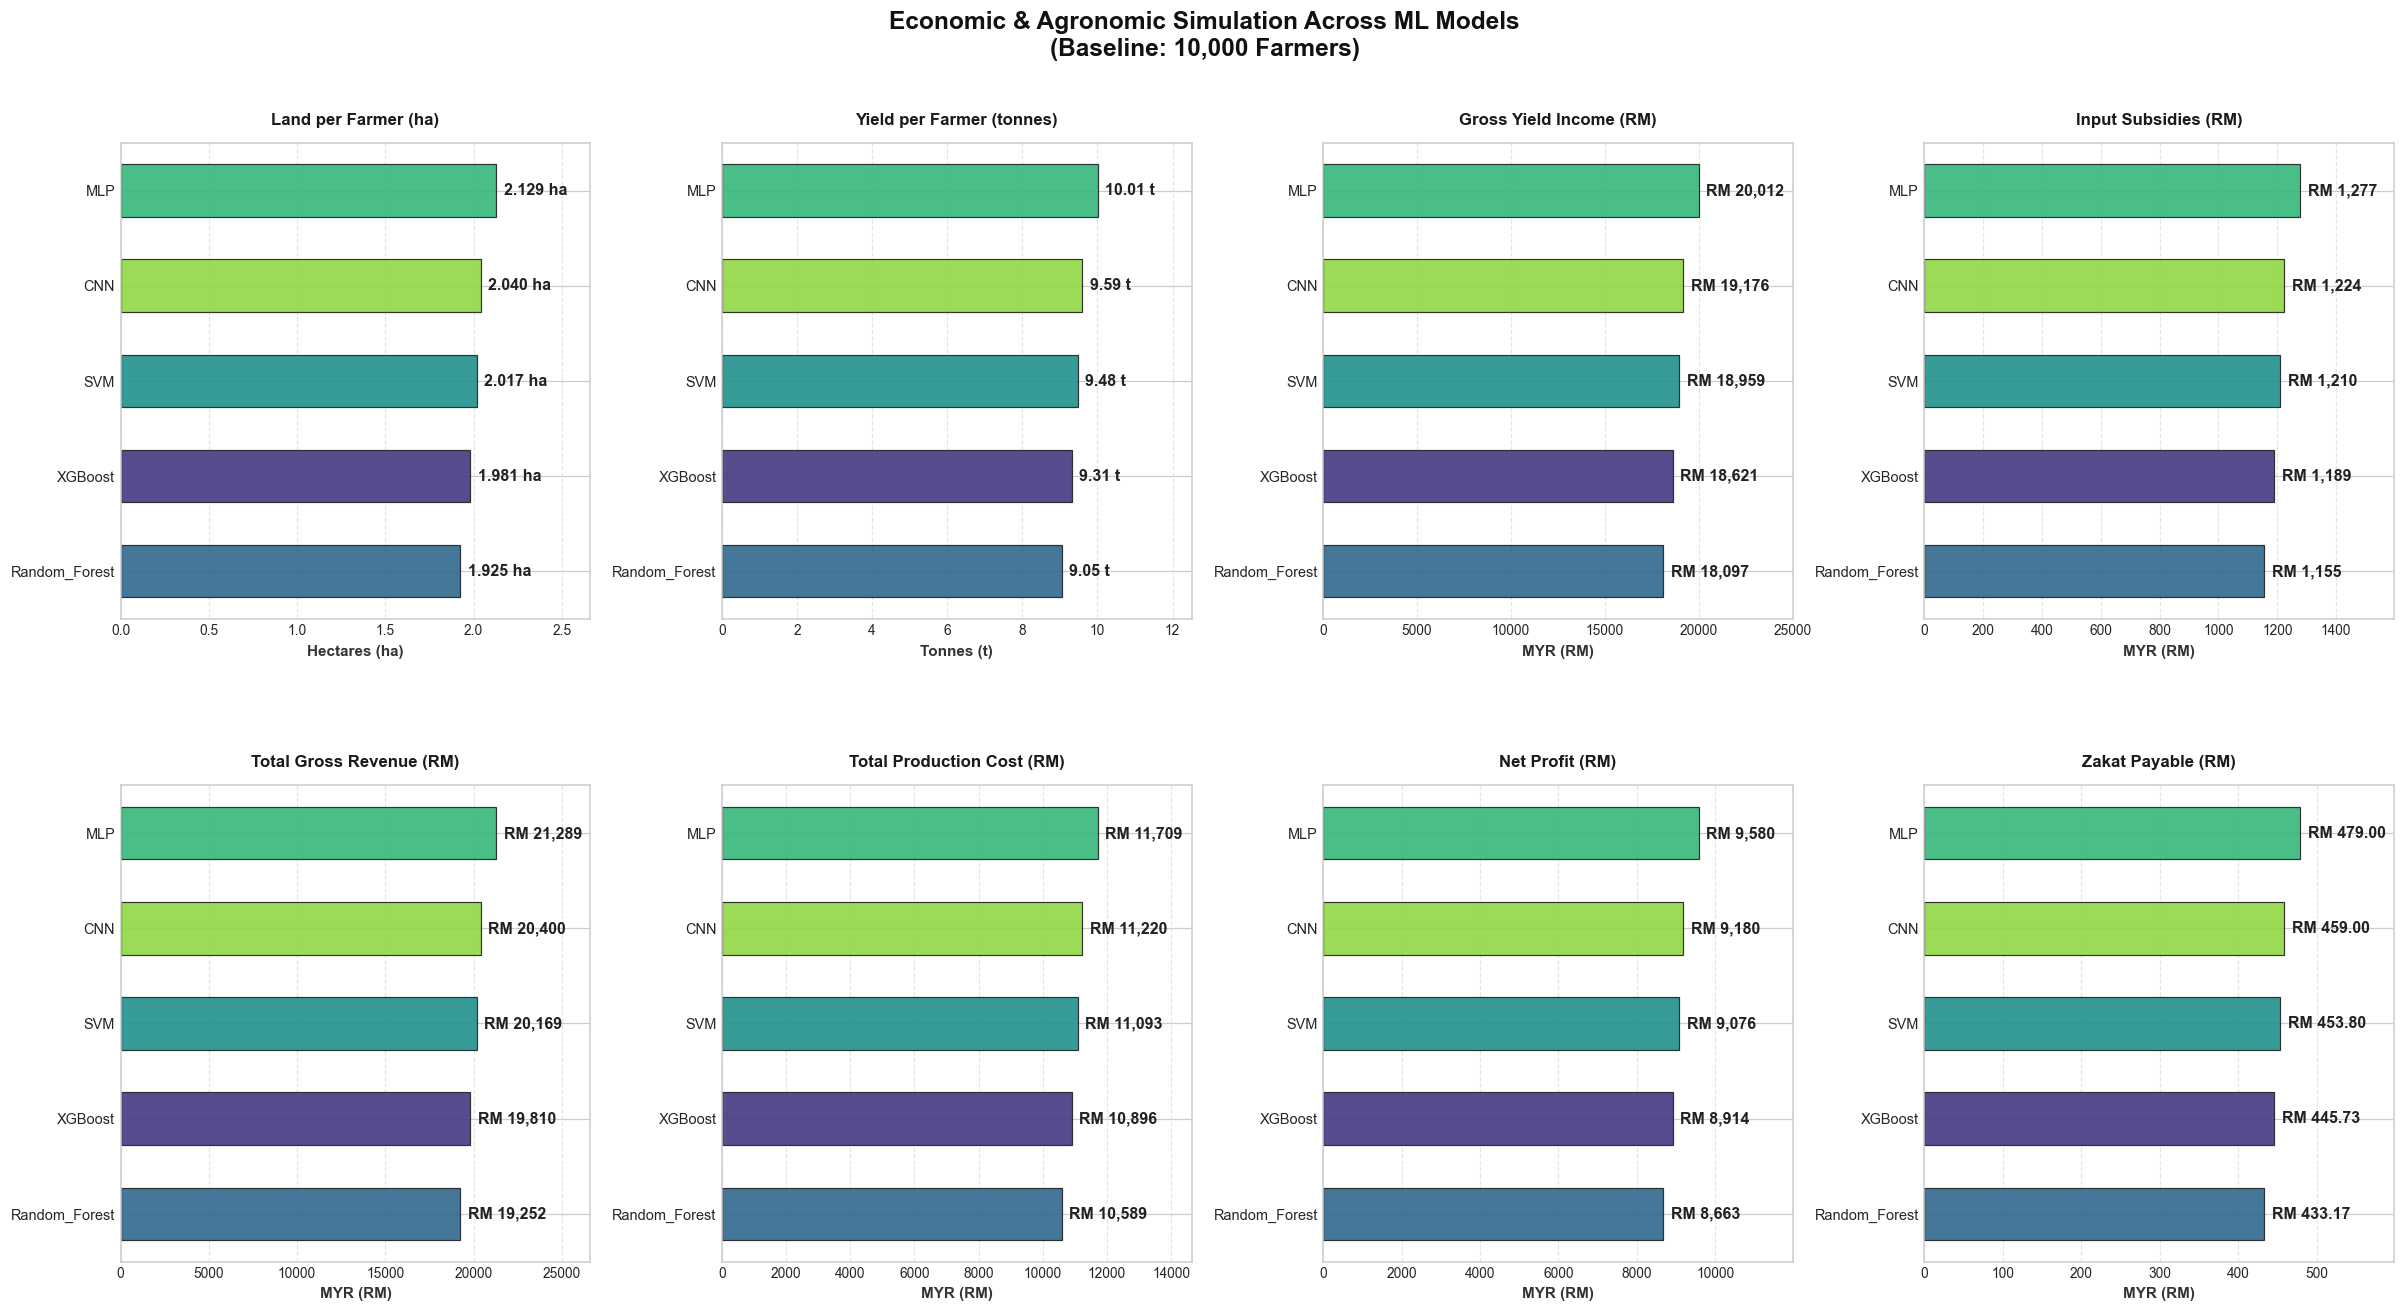

In [6]:
# ============================================================
# STEP (5): YIELD PRODUCTION & ECONOMIC SIMULATION
# ============================================================
# Print a newline and a decorative border of equals signs to the console
print("\n" + "="*50)
# Print the title of this step to indicate the start of the economic analysis phase
print("STEP 5: YIELD PRODUCTION & ECONOMIC SIMULATION")
# Print a closing decorative border for the section header
print("="*50)

# Constants & Benchmarks
# Define the assumed total number of farmers operating in the study area for the simulation
TOTAL_FARMERS = 10000
# Set the benchmark average paddy yield in metric tonnes per hectare
AVG_YIELD_PER_HA = 4.7         # metric tonnes
# Set the standard base purchasing price of harvested paddy per metric tonne in RM (Ringgit Malaysia)
BASE_PRICE_PER_TONNE = 1500.0  # RM
# Set the government price subsidy (Skim Subsidi Harga Padi) received per metric tonne in RM
SSHP_PER_TONNE = 500.0         # RM (Skim Subsidi Harga Padi)
# Set the government financial assistance provided for land plowing per hectare in RM
PLOWING_SUBSIDY_HA = 300.0     # RM
# Set the government financial assistance provided for agricultural inputs (fertilizer/pesticides) per hectare in RM
INPUT_SUBSIDY_HA = 300.0       # RM (Fertilizer/Pesticides)
# Set the estimated total operational and production cost incurred per hectare in RM
PRODUCTION_COST_HA = 5500.0    # RM
# Set the Islamic alms tax (Zakat) rate applied to the net profit (5%)
ZAKAT_RATE = 0.05              # 5% on net profit

# Initialize an empty list to store the calculated economic metrics for each ML model's prediction
economic_results = []

# Loop through the area_estimates dictionary to perform the economic simulation for every evaluated machine learning model
for model_name, estimated_paddy_area in area_estimates.items():
    # Print a sub-header indicating which model's area estimation is currently being analyzed
    print(f"\n--- Economic Simulation for {model_name} (Based on 10,000 Farmers) ---")
    
    # 1. Per Farmer Allocations & Yield
    # Calculate the average land area (in hectares) allocated to each farmer by dividing total estimated paddy area by total farmers
    land_per_farmer = estimated_paddy_area / TOTAL_FARMERS
    # Calculate the expected harvest yield (in tonnes) per farmer based on their allocated land and the benchmark yield rate
    yield_per_farmer = land_per_farmer * AVG_YIELD_PER_HA
    
    # 2. Revenue Calculations
    # Calculate the total income from selling the crop, combining the base market price and the price subsidy per tonne
    gross_yield_income = yield_per_farmer * (BASE_PRICE_PER_TONNE + SSHP_PER_TONNE)
    # Calculate the total area-based government financial assistance (plowing and inputs) received per farmer
    total_subsidies = land_per_farmer * (PLOWING_SUBSIDY_HA + INPUT_SUBSIDY_HA)
    # Calculate the overall gross revenue per farmer by adding the crop sales income and the area-based subsidies
    total_gross_revenue = gross_yield_income + total_subsidies
    
    # 3. Cost & Profit Calculations
    # Calculate the total operational costs incurred by the farmer based on their land size
    total_production_cost = land_per_farmer * PRODUCTION_COST_HA
    # Calculate the final net profit per farmer by subtracting total production costs from the total gross revenue
    net_profit = total_gross_revenue - total_production_cost
    
    # 4. Zakat Calculation
    # Calculate the Zakat (religious tax) amount owed per farmer by applying the 5% rate to their net profit
    zakat_payable = net_profit * ZAKAT_RATE
    
    # 5. Store and Output Results
    # Append all calculated economic metrics for the current model as a dictionary into the economic_results list
    economic_results.append({
        "Model": model_name,
        "Total Paddy Area (ha)": estimated_paddy_area,
        "Land per Farmer (ha)": land_per_farmer,
        "Yield per Farmer (tonnes)": yield_per_farmer,
        "Gross Yield Income (RM)": gross_yield_income,
        "Input Subsidies (RM)": total_subsidies,
        "Total Gross Revenue (RM)": total_gross_revenue,
        "Total Production Cost (RM)": total_production_cost,
        "Net Profit (RM)": net_profit,
        "Zakat Payable (RM)": zakat_payable
    })
    
    # Print the calculated land allocation per farmer to 4 decimal places
    print(f"Land Allocation       : {land_per_farmer:.4f} ha / farmer")
    # Print the calculated crop yield per farmer to 3 decimal places
    print(f"Yield Production      : {yield_per_farmer:.3f} tonnes / farmer")
    # Print the gross income from the yield, formatted as currency with commas and 2 decimal places
    print(f"Gross Yield Income    : RM {gross_yield_income:,.2f}")
    # Print the total area-based subsidies received, formatted as currency
    print(f"Input Subsidies       : RM {total_subsidies:,.2f}")
    # Print the combined total gross revenue, formatted as currency
    print(f"Total Gross Revenue   : RM {total_gross_revenue:,.2f}")
    # Print the total operational and production costs, formatted as currency
    print(f"Total Production Cost : RM {total_production_cost:,.2f}")
    # Print the calculated net profit per farmer, formatted as currency
    print(f"Net Profit            : RM {net_profit:,.2f}")
    # Print the estimated Zakat obligation per farmer, formatted as currency
    print(f"Estimated Zakat (5%)  : RM {zakat_payable:,.2f}")

# Convert the list of dictionary results into a pandas DataFrame and set the 'Model' name as the row index for structured viewing
eco_df = pd.DataFrame(economic_results).set_index("Model")
# Export the finalized economic simulation DataFrame to a CSV file in the designated output directory for reporting
#eco_df.to_csv(os.path.join(OUTPUT_DIR, "Economic_Simulation_Results.csv"))

# Load the simulation results CSV and reset the index so 'Model' is a column again
econ_simu = eco_df.copy().reset_index()

# Set visual aesthetic styling
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9.5
})

# Define the 8 metrics with specific formatting
metrics_config = [
    {"col": "Land per Farmer (ha)",        "unit": "Hectares (ha)",  "fmt": "{:.3f} ha"},
    {"col": "Yield per Farmer (tonnes)",    "unit": "Tonnes (t)",     "fmt": "{:.2f} t"},
    {"col": "Gross Yield Income (RM)",     "unit": "MYR (RM)",       "fmt": "RM {:,.0f}"},
    {"col": "Input Subsidies (RM)",        "unit": "MYR (RM)",       "fmt": "RM {:,.0f}"},
    {"col": "Total Gross Revenue (RM)",    "unit": "MYR (RM)",       "fmt": "RM {:,.0f}"},
    {"col": "Total Production Cost (RM)",  "unit": "MYR (RM)",       "fmt": "RM {:,.0f}"},
    {"col": "Net Profit (RM)",             "unit": "MYR (RM)",       "fmt": "RM {:,.0f}"},
    {"col": "Zakat Payable (RM)",          "unit": "MYR (RM)",       "fmt": "RM {:,.2f}"}
]

# Set up a 2 x 4 subplot canvas
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(22, 12))
axes = axes.flatten()

# Lock each model to a distinct color palette entry so identities stay consistent
unique_models = econ_simu["Model"].unique().tolist()
model_color_map = dict(zip(unique_models, sns.color_palette("viridis", len(unique_models))))

for i, cfg in enumerate(metrics_config):
    ax = axes[i]
    col_name = cfg["col"]
    unit_label = cfg["unit"]
    fmt_str = cfg["fmt"]
    
    # Sort dataframe descending (highest to lowest) for the current metric
    sorted_df = econ_simu.sort_values(by=col_name, ascending=False).reset_index(drop=True)
    models_sorted = sorted_df["Model"].tolist()
    bar_colors = [model_color_map[m] for m in models_sorted]
    
    # Plot horizontal bars
    bars = ax.barh(
        models_sorted, 
        sorted_df[col_name], 
        color=bar_colors, 
        height=0.55, 
        edgecolor="#222222", 
        linewidth=0.8, 
        alpha=0.9
    )
    
    # Invert y-axis so the highest value (first row) sits at the top
    ax.invert_yaxis()
    
    # Titles and axis formatting
    ax.set_title(col_name, fontweight="bold", pad=12, color="#1a1a1a")
    ax.set_xlabel(unit_label, fontweight="semibold", color="#333333")
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    
    # Provide ~25% headroom on the right for clean text annotation placement
    max_val = sorted_df[col_name].max()
    ax.set_xlim(0, max_val * 1.25 if max_val > 0 else 1)
    
    # Direct value annotations placed directly to the right of each horizontal bar
    for bar in bars:
        w = bar.get_width()
        y = bar.get_y() + bar.get_height() / 2
        ax.annotate(
            fmt_str.format(w),
            xy=(w, y),
            xytext=(5, 0),
            textcoords="offset points",
            ha="left", 
            va="center",
            fontsize=10.5, 
            fontweight="bold",
            color="#222222"
        )

# Main title
plt.suptitle(
    "Economic & Agronomic Simulation Across ML Models\n(Baseline: 10,000 Farmers)",
    fontsize=16, 
    fontweight="bold", 
    color="#111111",
    y=0.99
)

plt.tight_layout()
plt.subplots_adjust(top=0.89, hspace=0.35, wspace=0.28)

# Save high-resolution PNG
#output_file = "Economic_Simulation_Dashboard_Sorted.png"
#plt.savefig(output_file, dpi=300, bbox_inches="tight")
plt.show()

### **5.6 Economic and Agronomic Simulation Across Machine Learning Models**

To translate the satellite-derived paddy classifications into actionable socioeconomic intelligence, an automated agronomic and financial simulation (Step 5) was executed across all five machine learning architectures. By distributing the total predicted paddy acreage of each model equally across a baseline cohort of **10,000 smallholder farmers** in the Pendang district, the pipeline evaluates how spatial classification variations propagate into farm-level livelihoods, government subsidy allocations, operational costs, and *zakat* obligations.

Table 5.3 summarizes the complete agronomic and economic simulation results per farmer across the five evaluated models, alongside the standardized per-hectare financial rates.

**Table 5.3: Comparative Agronomic & Economic Simulation Results Across Models (Baseline: 10,000 Farmers)**

| Economic / Agronomic Component | Baseline Benchmark / Rate | Random Forest (19,252 ha) | XGBoost (19,810 ha) | SVM (20,169 ha) | CNN (20,400 ha) | MLP (21,289 ha) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **1. Land Allocation per Farmer** | $1.8462\text{ ha/farmer}$ *(PBT)* <br>*(or $\text{Total Area} \div 10,000$)* | **1.9252 ha** | 1.9810 ha | 2.0169 ha | 2.0400 ha | 2.1289 ha |
| **2. Yield Production per Farmer** | $4.70\text{ tonnes/ha}$ | **9.048 tonnes** | 9.311 tonnes | 9.479 tonnes | 9.588 tonnes | 10.006 tonnes |
| **3. Gross Yield Income** *(Base + SSHP)* | $\text{RM } 9,400.00\text{/ha}$ | **RM 18,096.88** | RM 18,621.40 | RM 18,958.86 | RM 19,176.00 | RM 20,011.66 |
| **4. Input Subsidies** *(Plowing + Fertilizer)* | $\text{RM } 600.00\text{/ha}$ | **RM 1,155.12** | RM 1,188.60 | RM 1,210.14 | RM 1,224.00 | RM 1,277.34 |
| **5. Total Gross Revenue** | $\text{RM } 10,000.00\text{/ha}$ | **RM 19,252.00** | RM 19,810.00 | RM 20,169.00 | RM 20,400.00 | RM 21,289.00 |
| **6. Total Production Cost** | $\text{RM } 5,500.00\text{/ha}$ | **RM 10,588.60** | RM 10,895.50 | RM 11,092.95 | RM 11,220.00 | RM 11,708.95 |
| **7. Net Profit** *(Take-Home Income)* | $\text{RM } 4,500.00\text{/ha}$ | **RM 8,663.40** | RM 8,914.50 | RM 9,076.05 | RM 9,180.00 | RM 9,580.05 |
| **8. Estimated Zakat Payable (5%)** | $\text{RM } 225.00\text{/ha}$ | **RM 433.17** | RM 445.73 | RM 453.80 | RM 459.00 | RM 479.00 |

---

#### **5.6.1 Agronomic Allocation: Land per Farmer (ha) and Yield Production (tonnes)**

* **Land Allocation per Farmer (ha):** Under an equitable distribution across 10,000 smallholders, the estimated farm size per household ranges from a conservative **1.9252 ha** under **Random Forest** and **1.9810 ha** under **XGBoost**, to **2.0169 ha** (**SVM**), **2.0400 ha** (**CNN**), and a high of **2.1289 ha** under **MLP**. These figures closely mirror empirical field surveys in the Muda Agricultural Development Authority (MADA) region, where the average operational farm size per smallholder household sits at approximately $1.9\text{ to }2.1\text{ hectares}$ (Omar et al., 2024). Furthermore, when benchmarked against PBT Kedah's official district-wide ground truth ($18,462.00\text{ ha}$, or $1.8462\text{ ha/farmer}$), **Random Forest** deviates by only $+0.0790\text{ ha}$ ($+4.28\%$) per farmer, whereas **MLP** over-allocates land by $+0.2827\text{ ha}$ ($+15.31\%$) per farmer due to false-positive pixel classifications in the eastern uplands.

* **Yield Production per Farmer (tonnes):** Applying the regional MADA harvest benchmark of **4.7 metric tonnes per hectare** (Ministry of Agriculture and Food Security, 2024), seasonal paddy production scales proportionally with land size. **Random Forest** projects an individual harvest of **9.048 tonnes/farmer** ($90,484.4\text{ tonnes}$ district-wide), followed by **XGBoost** at **9.311 tonnes/farmer** ($93,107.0\text{ tonnes}$ district-wide). Conversely, **SVM**, **CNN**, and **MLP** project higher yields of **9.479 tonnes**, **9.588 tonnes**, and **10.006 tonnes per farmer**, respectively. Maintaining high spatial precision during Step 4 is therefore vital for national food security accounting, as MLP's spatial over-estimation inflates district-wide grain supply projections by **9,573.9 tonnes** compared to Random Forest (Dorairaj & Govender, 2023).

---

#### **5.6.2 Revenue Composition: Gross Yield Income, Input Subsidies, and Total Gross Revenue**

* **Gross Yield Income (RM):** Gross yield income combines the base mill gate market price ($\text{RM } 1,500\text{/tonne}$) with the federal *Skim Subsidi Harga Padi* (SSHP) price support ($\text{RM } 500\text{/tonne}$), generating an effective payout of **RM 2,000 per metric tonne** or **RM 9,400 per hectare** (Bernama, 2023). Across the models, gross crop earnings per smallholder range from **RM 18,096.88** (**Random Forest**) and **RM 18,621.40** (**XGBoost**) up to **RM 20,011.66** (**MLP**). Crucially, the RM 500/tonne SSHP component alone contributes **25.0%** of the gross yield income (ranging from **RM 4,524.22** in Random Forest to **RM 5,002.92** in MLP), acting as a vital buffer against market price volatility (Bernama, 2023).

* **Input Subsidies (RM):** In addition to price support, smallholders receive area-based federal input incentives totaling **RM 600 per hectare**, comprising **RM 300/ha** for plowing (*Insentif Pembajakan*) and **RM 300/ha** for fertilizers and pesticides (Business Today, 2026). This translates into direct input assistance of **RM 1,155.12/farmer** under **Random Forest**, **RM 1,188.60/farmer** under **XGBoost**, **RM 1,210.14/farmer** under **SVM**, **RM 1,224.00/farmer** under **CNN**, and **RM 1,277.34/farmer** under **MLP**. From a public finance perspective, relying on an over-predicting model like MLP ($21,289\text{ ha}$) instead of Random Forest ($19,252\text{ ha}$) would cause policymakers to over-budget district-wide input subsidies by **RM 1,222,200** per planting season.

* **Total Gross Revenue (RM):** Combining gross yield income ($\text{RM } 9,400\text{/ha}$) and input subsidies ($\text{RM } 600\text{/ha}$) yields a standardized gross revenue of exactly **RM 10,000 per hectare**. Consequently, total seasonal gross revenue per smallholder stands at **RM 19,252.00** (**Random Forest**), **RM 19,810.00** (**XGBoost**), **RM 20,169.00** (**SVM**), **RM 20,400.00** (**CNN**), and **RM 21,289.00** (**MLP**). Across all models, combined government interventions ($\text{RM } 2,350\text{/ha}$ from SSHP plus $\text{RM } 600\text{/ha}$ from input subsidies = $\text{RM } 2,950\text{/ha}$) account for **29.50% of total gross revenue**.

---

#### **5.6.3 Cost Structure and Profitability: Total Production Cost and Net Profit**

* **Total Production Cost (RM):** Modern commercial paddy cultivation in the MADA granary requires substantial capital expenditure averaging **RM 5,500 per hectare** to cover mechanized land preparation, combine harvester rentals, certified seeds, agrochemicals, hired labor, and grain transport (Omar et al., 2024). In the simulation, seasonal production costs per farmer amount to **RM 10,588.60** (**Random Forest**), **RM 10,895.50** (**XGBoost**), **RM 11,092.95** (**SVM**), **RM 11,220.00** (**CNN**), and **RM 11,708.95** (**MLP**). Operational costs therefore absorb **55.0% of total gross revenue**, representing the primary financial burden on rural smallholders (Omar et al., 2024).

* **Net Profit (RM):** After deducting total production costs ($\text{RM } 5,500\text{/ha}$) from total gross revenue ($\text{RM } 10,000\text{/ha}$), each hectare generates a net profit of **RM 4,500.00** (a **45.0% net profit margin**). Per-farmer seasonal net profit is projected at **RM 8,663.40** under **Random Forest** and **RM 8,914.50** under **XGBoost**, rising to **RM 9,076.05** (**SVM**), **RM 9,180.00** (**CNN**), and **RM 9,580.05** (**MLP**). Assuming a standard 5-to-6-month cultivation cycle (two seasons per year), the most realistic model (**Random Forest**) indicates an average monthly net household income of approximately **RM 1,443.90 to RM 1,732.68** from paddy farming alone.

* **Criticality of State Subsidies to Net Profitability:** A key structural insight from this simulation is that without the **RM 2,950/ha** combined subsidy package (SSHP + input subsidies), the unsubsidized net profit would drop from **RM 4,500/ha** to just **RM 1,550/ha**. Under the **Random Forest** baseline, removing government subsidies would slash a farmer's seasonal take-home pay by **65.56%**, from **RM 8,663.40** down to **RM 2,984.06** (under RM 500/month), confirming that federal price and input supports are indispensable in keeping Kedah's rice farming community above the rural poverty line (Bernama, 2023; Dorairaj & Govender, 2023; Omar et al., 2024).

---

#### **5.6.4 Socio-Religious Fiscal Impact: Estimated Zakat Payable (5%)**

* **Fulfillment of the *Nisab* Threshold:** Under the statutory guidelines of **Lembaga Zakat Negeri Kedah (LZNK)**, paddy harvests are subject to *zakat* once total yield reaches the minimum exemption limit (*nisab*) of **1,306 kg (1.306 metric tonnes)** per season (Lembaga Zakat Negeri Kedah, n.d.). Because all five machine learning models project average yields between **9.048 tonnes** (**Random Forest**) and **10.006 tonnes** (**MLP**) per farmer which is nearly seven times the minimum *nisab* threshold where the harvest comfortably qualifies for mandatory *zakat* collection across the entire smallholder cohort.

* **Zakat Calculation and Community Redistribution:** For commercial paddy fields utilizing modern irrigation infrastructure, mechanical plowing, and paid labor, LZNK stipulates a **5% zakat rate calculated on net income** after production cost deductions (Lembaga Zakat Negeri Kedah, n.d.). At $\text{RM } 225.00\text{/ha}$, the estimated *zakat* payable per farmer is **RM 433.17** (**Random Forest**), **RM 445.73** (**XGBoost**), **RM 453.80** (**SVM**), **RM 459.00** (**CNN**), and **RM 479.00** (**MLP**).

* **District-Wide Zakat Revenue Projections:** Aggregated across all 10,000 farmers in Pendang, the optimal **Random Forest** model estimates a total seasonal *zakat* contribution of **RM 4,331,700.00** (or **RM 8.66 million annually** across two planting seasons), whereas **XGBoost** estimates **RM 4,457,250.00** per season. This demonstrates that coupling Earth Observation pipelines with economic modeling provides religious and state authorities with a transparent, auditable tool to forecast agricultural *zakat* collections and plan rural *asnaf* (beneficiary) wealth redistribution programs in Kedah (Lembaga Zakat Negeri Kedah, n.d.).

---

#### <h2 style="text-align: center;">**6.0 FUTURE RECOMMENDATIONS**</h2>

---

While the automated Earth Observation and machine learning pipeline developed in this study successfully delineated paddy cultivation across the Pendang district and achieved strong alignment with the official **Pihak Berkuasa Tempatan (PBT) Kedah** land-use benchmark (**18,462.00 ha**), several technical and methodological refinements can be implemented in future iterations to further enhance spatial precision, algorithmic generalization, and socioeconomic modeling accuracy.

---

### **6.1 Increasing Satellite Spatial Resolution from 100 m to 10 m or 20 m**

* **Addressing the Mixed-Pixel Effect:** In the current workflow, all 18 multi-spectral, radar, and nighttime light variables were standardized and extracted at a **100 m × 100 m** spatial resolution (**1.0 hectare per pixel**). At this coarser scale, single pixels along the fragmented central transitional zone (`100.50°E` to `100.58°E`) frequently span multiple land-cover types such as narrow paddy plots bordering village orchards (*kampung*), seasonal scrubland, and rural roads resulting in edge-classification ambiguity and false-positive over-predictions.

* **Sub-Pixel Infrastructure Delineation:** Furthermore, a **100 m** pixel absorbs internal, non-planted farm infrastructure including earth bunds (*batas*), secondary irrigation canals, drainage ditches, and farm access tracks into the surrounding vegetative signal which contributed to the **+4.28% (+790.00 ha)** gross-to-net area surplus observed even in the top-performing **Random Forest** model (**19,252.00 ha** vs. PBT Kedah's **18,462.00 ha**).

* **Implementation Strategy:** Future work should extract Sentinel-1 (`SAR_VH`, `SAR_VV`) and visible/near-infrared Sentinel-2 indices (`NDVI`, `NDWI`, `EVI`, `SAVI`, `MSAVI`) at their native **10-meter resolution** (**0.01 ha per pixel**, a 100-fold increase in spatial detail), and shortwave-infrared indices (`MNDWI`, `NDBI`, `BSI`, `UI`, `AWEI`) at their native **20-meter resolution** (**0.04 ha per pixel**). Operating at **10 m to 20 m** resolution will enable the classifiers to sharply resolve individual parcel boundaries, exclude non-planted canal networks, and test whether finer spatial granularity significantly reduces the gap between satellite-derived predictions and official cadastral records (Fatchurrachman et al., 2022).

---

### **6.2 Implementing Advanced Training Dataset Resampling and Class-Balancing Techniques**

* **Mitigating Asymmetric False Positive Rates:** Evaluation on the hold-out test set revealed that while the models achieved high sensitivity (94.1%–96.0% recall), they exhibited a consistent **9.8% to 11.8% False Positive rate** ($10\text{ to }12$ non-paddy samples misclassified as paddy). When deployed across the full Pendang study area where approximately **70% of the landmass is non-paddy**; this ~10% commission error rate compounds across thousands of upland and wetland pixels, driving systematic area over-estimation (most notably in **MLP** at **21,289.00 ha** and **CNN** at **20,400.00 ha**).

* **Algorithmic Resampling:** Future iterations should experiment with statistical resampling techniques on the training matrix prior to model fitting, including **Synthetic Minority Over-sampling Technique (SMOTE)**, **Adaptive Synthetic Sampling (ADASYN)**, and **Tomek Links** or **Edited Nearest Neighbors (ENN)** under-sampling to clean noisy, overlapping decision boundaries between lowland paddy and waterlogged non-paddy classes (Suryono et al., 2022).

* **Targeted Spatial Re-Sampling of Hard Negatives:** In addition to algorithmic resampling, the ground-truth dataset integrated in Step 3 (which enforces a **50-meter maximum matching threshold** in **EPSG:3375**) should be spatially augmented with targeted "hard negative" samples collected specifically from the central transitional ecotone and eastern riparian floodplains. Supplying the models with more representative samples of swampy grasslands, fallow plots, and young oil palm estates will directly suppress Type I (False Positive) errors.

* **Probability Threshold Tuning:** Rather than relying on the default **0.50** classification probability cutoff during `predict_proba()` inference, future pipelines can utilize the generated Precision-Recall and Calibration curves to tune an optimal decision threshold (e.g., **0.55 to 0.65**) that equalizes False Positive and False Negative rates for unbiased district-wide area estimation.

---

### **6.3 Expanding from Binary Classification to Multi-Class Land Use and Land Cover (LULC) Classification**

* **Deconstructing the Heterogeneous "Non-Paddy" Class:** In the current binary framework (`paddy_label` = `0` or `1`), approximately **70% of Pendang's landmass (~45,000 ha)** is compressed into a single, monolithic "Non-Paddy" category. However, non-paddy terrain in Pendang is spectrally and structurally diverse, encompassing urban settlements, rural roads, bare/fallow land, inland water bodies, irrigation reservoirs, rubber estates, oil palm plantations, and tropical forests. Forcing algorithms to fit a single binary hyperplane around such a diverse negative class creates spectral confusion particularly when flooded paddy plots mimic open water bodies, or when newly harvested paddy fields mimic bare soil.

* **Full Utilization of the 18 Engineered Spectral & Radar Indices:** Notably, the 18 satellite variables engineered in Step 1 are already mathematically tailored to isolate specific multi-class land-cover types:
  * **Buildings & Urban Infrastructure:** Directly captured by `NDBI`, `BUI`, `IBI`, `UI`, and artificial night radiance `NTL` (Elvidge et al., 2013; He et al., 2010; Kawamura et al., 1996; Xu, 2008; Zha et al., 2003).
  * **Water Bodies & Irrigation Canals:** Explicitly delineated by `AWEI`, `MNDWI`, and `NDWI` combined with low specular `SAR_VV` backscatter (Feyisa et al., 2014; Filipponi, 2019; McFeeters, 1996; Xu, 2006).
  * **Bare Land & Cleared Soil:** Highlighted by `BSI`, `BI`, `NDSI`, and `SVI` (Escadafal, 1989; Rikimaru et al., 2002; Rogers & Kearney, 2004; Thompson et al., 2020).
  * **Forests & Perennial Tree Crops:** Distinguished from seasonal rice canopies by high, stable year-round biomass in `NDVI`, `EVI`, `SAVI`, `MSAVI`, and depolarized `SAR_VH` volume scattering (Filipponi, 2019; Huete, 1988; Huete et al., 2002; Qi et al., 1994; Rouse et al., 1974).

* **Multi-Class Algorithmic Implementation:** Future iterations should categorize training labels into discrete LULC classes (e.g., `0: Paddy Field`, `1: Built-Up/Buildings`, `2: Bare Land`, `3: Water Body`, `4: Forest/Tree Plantation`). In Step 4, the neural network architectures (**MLP** and **1D-CNN**) can be updated from a single sigmoid output node (`loss='binary_crossentropy'`) to a multi-node **Softmax** output layer (`loss='categorical_crossentropy'`), while **XGBoost** can be configured with the `multi:softprob` objective and evaluated via macro-averaged F1-scores. Allowing the models to explicitly learn the spectral signatures of buildings, bare land, water bodies, and forests will prevent transitional land cover from bleeding into the paddy class and produce a comprehensive district-wide LULC map.

---

### **6.4 Transitioning from Annual Median Composites to Multi-Temporal Phenological Time Series**

* **Overcoming Static Composite Limitations:** The current feature engineering pipeline relies on a single annual (2023) median composite across the 18 satellite variables. In a static full-year composite, permanently inundated marshes or seasonal floodplains in eastern Pendang can exhibit median `SAR_VH` backscatter and `MDWI`/`NDWI` moisture levels similar to cultivated rice paddies.

* **Phenology-Driven Feature Extraction:** Rice cultivation follows a distinct biological growth cycle characterized by three sequential phases: (1) *agronomic flooding and transplanting* (high `MDWI`/`AWEI` water signal, sharp drop in `SAR_VH`), (2) *vegetative tillering and heading* (rapid surge in `NDVI`/`EVI` and `SAR_VH` volume scattering), and (3) *harvesting and bare-soil fallow* (sharp drop in `NDVI`, spike in `BSI`/`NDSI`) (dela Torre et al., 2021; Fatchurrachman et al., 2022).

* **Sequential Deep Learning Architectures:** By extracting monthly or bi-weekly time-series stacks across MADA's two annual planting seasons (*Musim 1* and *Musim 2*), future studies can deploy temporal deep learning models such as **Long Short-Term Memory (LSTM)** networks, **Temporal Convolutional Networks (TCN)**, or **Spatiotemporal 3D-CNNs**. Tracking the temporal rate of change ($\Delta\text{SAR\_VH}$ and $\Delta\text{NDVI}$) across growth stages will allow the pipeline to separate true double-cropped and single-cropped paddy fields from static natural wetlands (dela Torre et al., 2021).

---

### **Summary Table of Future Recommendations**

| Recommendation Area | Current Pipeline Baseline | Proposed Future Enhancement | Expected Impact on Findings |
| :--- | :--- | :--- | :--- |
| **1. Spatial Resolution** | **100 m × 100 m** ($1.0\text{ ha/pixel}$) GeoTIFF grids. | Native **10 m** (VNIR/SAR) and **20 m** (SWIR) Sentinel grids. | Eliminates mixed boundary pixels and excludes sub-pixel farm bunds/canals. |
| **2. Dataset Resampling** | Stratified 80/20 split with 50 m nearest-neighbor matching. | **SMOTE / ADASYN**, hard-negative ecotone sampling, & threshold tuning. | Reduces the ~10% False Positive rate and curbs upland area over-prediction. |
| **3. Multi-Class Classification** | Binary classification (`0: Non-Paddy`, `1: Paddy`). | Multi-class LULC (`Paddy`, `Buildings`, `Bare Land`, `Water Body`, `Forest`). | Prevents spectral confusion between flooded/fallow fields and water/bare soil; utilizes all 18 indices. |
| **4. Temporal Representation** | Single full-year (2023) median composite. | Multi-temporal phenological stacks (*Musim 1 & 2*) with **LSTM / 3D-CNN**. | Separates cyclical rice growth stages from static swamps and fallow wetlands. |

---

#### <h2 style="text-align: center;">**7.0 CONCLUSION**</h2>

---

This study successfully designed and executed an automated, end to end Earth Observation (EO) and machine learning pipeline to map paddy cultivation across the Pendang district of Kedah and translate satellite derived land estimates into farm level socioeconomic projections. By integrating 18 multispectral, radar, and nighttime light variables through rigorous spatial preprocessing, including K Nearest Neighbors ($k=10$) missing data imputation, Yeo Johnson power transformation, Min Max scaling, and 50 meter nearest neighbor ground truth matching in `EPSG:3375`, the workflow established a reliable geospatial baseline for evaluating five advanced classification architectures: **Random Forest (RF)**, **eXtreme Gradient Boosting (XGBoost)**, **Support Vector Machine (SVM)**, **Multilayer Perceptron (MLP)**, and **1D Convolutional Neural Network (CNN)**.

---

### **7.1 Synthesis of Algorithmic Performance and Physical Drivers**

1. **Superiority of Tree Based Ensembles:** Quantitative validation on the 20% stratified hold out test set and 5 fold Spatial Block Cross Validation (2 km grid blocks) demonstrated that **Random Forest** achieved the highest predictive fidelity, recording an **Overall Accuracy of 93.10%**, a **Sensitivity (Recall) of 96.04%** (missing only 4 out of 101 actual paddy plots), and an **F1 Score of 93.27%**. **SVM** (**92.75% F1 Score**) and **XGBoost** (**92.23% F1 Score**) followed closely, whereas the neural architectures (**MLP** at **92.23% F1 Score** and **1D CNN** at **91.87% F1 Score**) exhibited higher commission errors in transitional upland zones.

2. **Dominance of C Band Synthetic Aperture Radar (`SAR`):** Feature importance analysis across all five models confirmed that Sentinel 1 active microwave backscatter (**`SAR_VH`** and **`SAR_VV`**) is the most decisive physical predictor for tropical paddy delineation in Kedah. Supported by topographic soil vulnerability (**`SVI`**), surface moisture indices (**`MDWI`**, **`NDWI`**), and anthropogenic exclusion masks (**`NTL`**, **`NDBI`**, **`UI`**), radar backscatter effectively penetrates perennial cloud cover to capture the structural transition from inundated puddled soil to vertical rice canopy development.

---

### **7.2 Reconciliation of Official Ground Truth (MADA vs. PBT Kedah)**

A central contribution of this project is the empirical reconciliation of two seemingly divergent official government benchmarks for Pendang: **Lembaga Kemajuan Pertanian Muda (MADA)** at **14,052.04 ha** and **Pihak Berkuasa Tempatan (PBT) Kedah** at **18,462.00 ha**. 

* Across the **64,892.00 ha** Pendang study area, the deployed models estimated total paddy extents of **19,252.00 ha** (**Random Forest**, **29.67%**), **19,810.00 ha** (**XGBoost**, **30.53%**), **20,169.00 ha** (**SVM**, **31.08%**), **20,400.00 ha** (**CNN**, **31.44%**), and **21,289.00 ha** (**MLP**, **32.81%**).

* Spatial mapping confirmed that while MADA's **14,052.04 ha** benchmark strictly accounts for gazetted, canal irrigated granary blocks in western Pendang, wall to wall satellite sensors naturally capture both the western granary core and approximately **4,410 ha** of independent, non granary fringe paddy fields (*padi luar jelapang*) distributed across central and eastern riverine floodplains.

* Consequently, the optimal **Random Forest** model (**19,252.00 ha**) aligns within **+4.28% (+790.00 ha)** of PBT Kedah's district wide inventory (**18,462.00 ha**), with the minor surplus attributable to the inclusion of sub pixel farm bunds, access tracks, and irrigation ditches within **100 m × 100 m** ($1.0\text{ ha}$) raster cells.

---

### **7.3 Socioeconomic and Fiscal Impact on Smallholder Livelihoods**

Coupling the spatial predictions with the Step 5 Agronomic and Economic Simulation (benchmarked across **10,000 smallholder farmers** at **4.7 tonnes/ha** yield, **RM 2,000/tonne** subsidized paddy price, **RM 600/ha** input incentives, and **RM 5,500/ha** production cost) yielded critical policy insights:

* **Realistic Livelihood Baseline:** Under the top performing **Random Forest** model, each farmer operates an average of **1.9252 ha** and harvests **9.048 tonnes** of paddy per season, generating **RM 18,096.88** in gross yield income, **RM 1,155.12** in input subsidies, and **RM 19,252.00** in total gross revenue. After deducting **RM 10,588.60** in operational costs, the farmer retains a seasonal **Net Profit of RM 8,663.40** (approximately **RM 1,444 to RM 1,733 per month**).

* **Indispensability of Federal Subsidies:** Government price support (*Skim Subsidi Harga Padi*, SSHP at RM 500/tonne) and input subsidies (RM 600/ha) collectively represent **29.50% of gross revenue** and **65.56% of net take home profit**. Without these interventions, seasonal net income per farmer under the Random Forest baseline would collapse from **RM 8,663.40** to **RM 2,984.06**, underscoring the vital role of federal fiscal support in sustaining rural livelihoods.

* **Fiscal Precision and *Zakat* Forecasting:** With individual harvests (approximately 9.05 to 10.01 tonnes) far exceeding the mandatory *nisab* threshold, the 5% *zakat* deduction yields **RM 433.17 per farmer** (**RM 4.33 million** district wide per season) under **Random Forest**, compared to **RM 479.00 per farmer** (**RM 4.79 million** district wide) under **MLP**. Selecting a high precision classifier like Random Forest prevents public agencies from over budgeting district wide input subsidies by **RM 1.22 million** and grain supply by **9,574 tonnes** per season relative to over predicting models like MLP.

---

### **7.4 Future Outlook and Operational Scalability**

To transition this prototype into a national scale agricultural monitoring system, future iterations should prioritize six strategic enhancements:
1. **Higher Spatial Resolution:** Upgrading from **100 m** grids to native **10 m and 20 m** Sentinel 1 and Sentinel 2 imagery to resolve narrow parcel boundaries and exclude sub pixel canal and bund infrastructure.

2. **Dataset Resampling and Threshold Tuning:** Applying **SMOTE and ADASYN**, targeted hard negative sampling in transitional ecotones, and probability threshold optimization to curb the 10% False Positive rate.

3. **Multiclass LULC Classification:** Expanding from binary classification (`Paddy` vs. `Non Paddy`) to **multiclass Land Use and Land Cover (LULC)** (`Paddy`, `Buildings`, `Bare Land`, `Water Body`, `Forest`) to fully leverage all 18 spectral and radar indices and eliminate class bleeding.

4. **Multitemporal Phenological Modeling:** Replacing static annual median composites with biweekly or monthly time series stacks across *Musim 1* and *Musim 2* using **LSTM** or **3D CNN** architectures to capture dynamic flooding to harvest growth curves.

Ultimately, this project demonstrates that combining multisensor Earth Observation data with spatially validated machine learning and econometric modeling provides Malaysian agricultural authorities (**KPKM**, **MADA**, **PBT Kedah**) and socioreligious institutions (**LZNK**) with a transparent, scalable, and cost effective decision support framework to safeguard national food security and rural farmer welfare.

---

#### <h2 style="text-align: center;">**REFERENCES**</h2>

---

Bernama. (2023, October 4). *Harga padi: Pesawah masih terima RM1,700 per tan, subsidi RM500 satu tan - Mohamad Sabu*. Astro Awani. https://www.astroawani.com/berita-malaysia/harga-padi-pesawah-masih-terima-rm1700-tan-subsidi-rm500-satu-tan-mohamad-sabu-440297

Bivand, R. S., Pebesma, E., & Gómez-Rubio, V. (2013). *Applied spatial data analysis with R* (2nd ed.). Springer.

Bolstad, P. (2016). *GIS fundamentals: A first text on geographic information systems* (5th ed.). Eider Press.

Breiman, L. (2001). Random forests. *Machine Learning*, *45*(1), 5–32.

Business Today. (2026, October 9). *Budget 2027: Paddy harvesting incentive doubled to RM100 per hectare*. Business Today Malaysia. https://www.facebook.com/businesstodayMY/posts/1737112011748272/

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794).

Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning*, *20*(3), 273–297.

dela Torre, D. M. G., Gao, J., Macinnis-Ng, C., & Shi, Y. (2021). Phenology-based delineation of irrigated and rain-fed paddy fields with Sentinel-2 imagery in Google Earth Engine. *Geo-spatial Information Science*, *24*(4), 695–710. https://doi.org/10.1080/10095020.2021.1984183

Dorairaj, D., & Govender, N. T. (2023). Rice and paddy industry in Malaysia: Governance and policies, research trends, technology adoption and resilience. *Frontiers in Sustainable Food Systems*, *7*, Article 1093605. https://doi.org/10.3389/fsufs.2023.1093605

Elvidge, C. D., Baugh, K. E., Zhizhin, M., & Hsu, F. C. (2013). Why VIIRS data are superior to DMSP for mapping nighttime lights. *Proceedings of the Asia-Pacific Advanced Network*, *35*(0), 62–69.

Escadafal, R. (1989). *Caractérisation de la surface des sols arides par observations de terrain et par télédétection*. ORSTOM.

Fatchurrachman, Rudiyanto, Soh, N. C., Shah, R. M., Giap, S. G. E., Setiawan, B. I., & Minasny, B. (2022). High-resolution mapping of paddy rice extent and growth stages across Peninsular Malaysia using a fusion of Sentinel-1 and 2 time series data in Google Earth Engine. *Remote Sensing*, *14*(8), Article 1875. https://doi.org/10.3390/rs14081875

Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters*, *27*(8), 861–874.

Feyisa, G. L., Meilby, H., Fensholt, R., & Proud, S. R. (2014). Automated Water Extraction Index: A new technique for surface water mapping using Landsat imagery. *Remote Sensing of Environment*, *140*, 23–35.

Filipponi, F. (2019). Sentinel-1 GRD preprocessing workflow. *Proceedings*, *18*(1), Article 11.

Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press.

Han, J., Pei, J., & Kamber, M. (2011). *Data mining: Concepts and techniques* (3rd ed.). Morgan Kaufmann.

He, C., Shi, P., Xie, D., & Zhao, Y. (2010). Improving the normalized difference built-up index to map urban built-up areas using a semiautomatic segmentation approach. *Remote Sensing Letters*, *1*(4), 213–221.

Huete, A. R. (1988). A soil-adjusted vegetation index (SAVI). *Remote Sensing of Environment*, *25*(3), 295–309.

Huete, A., Didan, K., Miura, T., Rodriguez, E. P., Gao, X., & Ferreira, L. G. (2002). Overview of the radiometric and biophysical performance of the MODIS vegetation indices. *Remote Sensing of Environment*, *83*(1-2), 195–213.

Kawamura, M., Jayamana, S., & Tsujiko, Y. (1996). Relation between social and environmental conditions in Colombo Sri Lanka and the urban index estimated by satellite remote sensing data. *International Archives of Photogrammetry and Remote Sensing*, *31*(B8), 321–326.

Lembaga Zakat Negeri Kedah (LZNK). (n.d.). *Zakat padi*. Jom Zakat Kedah. Retrieved October 12, 2026, from https://jom.zakatkedah.com.my/kirazakat/kz_padi.php

McFeeters, S. K. (1996). The use of the Normalized Difference Water Index (NDWI) in the delineation of open water features. *International Journal of Remote Sensing*, *17*(7), 1425–1432.

McKinney, W. (2010). Data structures for statistical computing in Python. In *Proceedings of the 9th Python in Science Conference* (pp. 51–56).

Ministry of Agriculture and Food Security. (2024). *Perangkaan agromakanan Malaysia 2023*. Kementerian Pertanian dan Keterjaminan Makanan (KPKM). https://www.kpkm.gov.my/images/08-petak-informasi/penerbitan/perangkaan-agromakanan/Perangkaan-Agromakanan-Malaysia-2023.pdf

Omar, N., et al. (2024). Factors effecting paddy productivity in the MADA regions, Malaysia. *Malaysian Management Journal*, *28*. https://e-journal.uum.edu.my/index.php/mmj/en/article/view/21278/8458

Qi, J., Chehbouni, A., Huete, A. R., Kerr, Y. H., & Sorooshian, S. (1994). A modified soil adjusted vegetation index. *Remote Sensing of Environment*, *48*(2), 119–126.

Rikimaru, A., Roy, P. S., & Miyatake, S. (2002). Tropical forest cover density mapping. *Tropical Ecology*, *43*(1), 39–47.

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schröder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., & Dormann, C. F. (2017). Cross-validation strategies for data with space, time and/or phylogenetic structure. *Ecography*, *40*(8), 913–929.

Rogers, A. S., & Kearney, M. S. (2004). Reducing signature variability in unmixing coastal marsh Thematic Mapper scenes using spectral indices. *International Journal of Remote Sensing*, *25*(12), 2317–2335.

Rouse, J. W., Haas, R. H., Schell, J. A., & Deering, D. W. (1974). Monitoring vegetation systems in the Great Plains with ERTS. *NASA Special Publication*, *351*, 309.

Sokolova, M., & Lapalme, G. (2009). A systematic analysis of performance measures for classification tasks. *Information Processing & Management*, *45*(4), 427–437.

Suryono, H., Kuswanto, H., & Iriawan, N. (2022). Two-phase stratified random forest for paddy growth phase classification: A case of imbalanced data. *Sustainability*, *14*(22), Article 15252. https://doi.org/10.3390/su142215252

Thompson, N. M., Hughes, C. N., Nuñez, A., Frankenberger, J. R., & Bowling, L. C. (2020). Economic and environmental trade-offs of the Soil Vulnerability Index. *Journal of Soil and Water Conservation*, *75*(4), 517–527.

Troyanskaya, O., Cantor, M., Sherlock, G., Brown, P., Hastie, T., Tibshirani, R., Botstein, D., & Altman, R. B. (2001). Missing value estimation methods for DNA microarrays. *Bioinformatics*, *17*(6), 520–525.

Xu, H. (2006). Modification of normalised difference water index (NDWI) to enhance open water features in remotely sensed imagery. *International Journal of Remote Sensing*, *27*(14), 3025–3033.

Xu, H. (2008). A new index for delineating built-up land features in satellite imagery. *International Journal of Remote Sensing*, *29*(14), 4269–4276.

Yeo, I. K., & Johnson, R. A. (2000). A new family of power transformations to improve normality or symmetry. *Biometrika*, *87*(4), 954–959.

Zha, Y., Gao, J., & Ni, S. (2003). Use of normalized difference built-up index in automatically mapping urban areas from TM imagery. *International Journal of Remote Sensing*, *24*(3), 583–594.